# GMRT 海底正断层自动识别 · 开发笔记本（研究部分）

这个笔记本研究**具体这组 GMRT 数据**，用统计和机器学习得出实现笔记本 `GMRT_fault_implementation.ipynb` 需要的核心参数。
第 14 步把参数打印成可以直接复制的形式，**由研究员手动抄写**到实现笔记本的第 5 步。两个笔记本之间不传递任何文件。
最后的第 16 步逐项输出每个参数，并可选导出一份**数据传递文件**（JSON），供网页版（PWA）直接上传导入；实现笔记本不读取它。

代码不定义任何函数或类，按步骤从上到下依次执行：

| 步骤 | 内容 |
|---|---|
| 0–4 | 配置；下载、读取、重投影、调理（与实现笔记本相同，独立运行） |
| 5 | 数据特征：功率谱与有效分辨率、白噪声、坡度和纹理方向 |
| 6 | 尺度选择：脊线坡度双高斯混合的双峰程度（Ashman D） |
| 7 | 坡度阈值：混合模型后验 |
| 8 | 零假设：相位随机化替代地形 |
| 9 | 在真实网格和替代地形上运行识别流水线（与实现笔记本第 6–13 步相同的代码） |
| 10 | 统计标定：target-decoy 错误发现率控制 |
| 11 | 哪些特征能区分真实地形与替代地形 |
| 12–13 | 机器学习：target-decoy 逻辑回归（交叉验证）与阈值 |
| 14 | **输出给实现笔记本的参数** |
| 15 | （仅 MAR 29°N）用 CD99 TOBI 侧扫做独立检验 |
| 16 | **数据导出**：逐项输出每个参数（数值、单位、来源），可选导出数据传递文件 |

## 0. 配置与导入

In [1]:
AOI_NAME = "mar29n"
BBOX = (-43.75, -42.55, 28.74, 29.36)        # (west, east, south, north)
GMRT_RES = "max"
RAW_DIR = f"data/gmrt/{AOI_NAME}"
SEED = 0                                      # 替代地形与交叉验证的随机种子
FDR_TARGET = 0.10                             # 目标错误发现率
N_SURROGATES = 4                              # 替代地形个数
RUN_TOBI_CHECK = True                         # 第 15 步（区域与 CD99 TOBI 覆盖区重叠时才运行；首次下载约 300 MB）
CD99_DIR = "data/raw"

In [2]:
import csv
import json
import os
import shutil
import time
import urllib.parse
import urllib.request

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import ndimage as ndi
from scipy.signal import oaconvolve
from scipy.spatial import cKDTree
from scipy.stats import theilslopes
from skimage.filters import apply_hysteresis_threshold
from skimage.morphology import skeletonize
import tifffile
from pyproj import Transformer

%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["figure.dpi"] = 80
os.makedirs(RAW_DIR, exist_ok=True)
print("numpy", np.__version__, "| tifffile", tifffile.__version__)

numpy 2.5.3 | tifffile 2026.10.15


## 1–4. 前置部分（与实现笔记本相同，在这里独立运行）

In [3]:
GRIDSERVER = "https://www.gmrt.org/services/GridServer"
west, east, south, north = BBOX
gmrt_files = {}
for layer in ("topo", "topo-mask"):
    out_path = os.path.join(RAW_DIR, f"gmrt_{layer}.tif")
    gmrt_files[layer] = out_path
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        print(f"{out_path} 已存在，跳过下载")
        continue
    query = urllib.parse.urlencode({"west": f"{west:.6f}", "east": f"{east:.6f}", "south": f"{south:.6f}",
                                    "north": f"{north:.6f}", "layer": layer, "format": "geotiff",
                                    "resolution": GMRT_RES})
    url = f"{GRIDSERVER}?{query}"
    for attempt in range(4):
        try:
            with urllib.request.urlopen(url, timeout=900) as resp, open(out_path + ".part", "wb") as fh:
                shutil.copyfileobj(resp, fh, length=1 << 20)
            if os.path.getsize(out_path + ".part") < 1024:
                raise RuntimeError("GridServer 没有返回网格")
            os.replace(out_path + ".part", out_path)
            print(f"已下载 {layer}: {os.path.getsize(out_path) / 1e6:.1f} MB")
            break
        except Exception as exc:
            print(f"{layer} 第 {attempt + 1} 次下载失败: {exc}")
            time.sleep(2 ** (attempt + 1))
    else:
        raise RuntimeError(f"无法下载 {url}")

data/gmrt/mar29n/gmrt_topo.tif 已存在，跳过下载
data/gmrt/mar29n/gmrt_topo-mask.tif 已存在，跳过下载


In [4]:
layers = {}
for layer, path in gmrt_files.items():
    with tifffile.TiffFile(path) as tif:
        page = tif.pages[0]
        scale = page.tags["ModelPixelScaleTag"].value
        tie = page.tags["ModelTiepointTag"].value
        gk = page.tags["GeoKeyDirectoryTag"].value
        layers[layer] = page.asarray().astype(np.float32)
    geokeys = {gk[k]: gk[k + 3] for k in range(4, len(gk), 4) if gk[k + 1] == 0}
    assert geokeys.get(1024) == 2 and geokeys.get(2048) == 4326, "GMRT 应返回 WGS84 经纬度网格"
    half = 0.5 if geokeys.get(1025, 1) == 1 else 0.0          # PixelIsArea: 连接点在像元角上
    DLON, DLAT = float(scale[0]), float(scale[1])
    LON0 = float(tie[3]) + (half - float(tie[0])) * DLON      # 像元 [0,0] 中心的经度
    LAT0 = float(tie[4]) - (half - float(tie[1])) * DLAT      # 像元 [0,0] 中心的纬度
topo = layers["topo"]
valid_src = np.isfinite(topo) & np.isfinite(layers["topo-mask"])   # topo-mask 有值 = 多波束数据
NY_SRC, NX_SRC = topo.shape
print(f"GMRT 网格 {NX_SRC} x {NY_SRC} 节点，间距 {DLON:.6f}° x {DLAT:.6f}°；多波束数据占 {valid_src.mean():.1%}")

GMRT 网格 2186 x 1294 节点，间距 0.000550° x 0.000481°；多波束数据占 88.5%


In [5]:
lat_c = LAT0 - 0.5 * (NY_SRC - 1) * DLAT
lon_c = LON0 + 0.5 * (NX_SRC - 1) * DLON
zone = int(np.floor((lon_c + 180.0) / 6.0)) % 60 + 1
EPSG = (32600 if lat_c >= 0 else 32700) + zone
deg_m = np.pi / 180.0 * 6378137.0
native_m = min(DLON * deg_m * np.cos(np.radians(lat_c)), DLAT * deg_m)
PX = float(max(5.0, 5.0 * np.floor(native_m / 5.0)))     # 原生地面间距向下取整到 5 m
to_utm = Transformer.from_crs("EPSG:4326", f"EPSG:{EPSG}", always_xy=True)
to_geo = Transformer.from_crs(f"EPSG:{EPSG}", "EPSG:4326", always_xy=True)

# 目标网格范围：把源网格四条边投影过去，取内接范围
lon_axis = LON0 + np.arange(NX_SRC) * DLON
lat_axis = LAT0 - np.arange(NY_SRC) * DLAT
b_lon = np.concatenate([lon_axis, np.full(NY_SRC, lon_axis[-1]), lon_axis[::-1], np.full(NY_SRC, lon_axis[0])])
b_lat = np.concatenate([np.full(NX_SRC, lat_axis[0]), lat_axis, np.full(NX_SRC, lat_axis[-1]), lat_axis[::-1]])
bx, by = to_utm.transform(b_lon, b_lat)
x_min, x_max = np.ceil(np.min(bx) / PX) * PX, np.floor(np.max(bx) / PX) * PX
y_min, y_max = np.ceil(np.min(by) / PX) * PX, np.floor(np.max(by) / PX) * PX
NX = int(round((x_max - x_min) / PX)) + 1
NY = int(round((y_max - y_min) / PX)) + 1
X0, Y0 = float(x_min), float(y_max)                         # 目标像元 [0,0] 的中心（西北角）

# 逆映射 + 双线性插值；只要有一个参与插值的源节点无效，目标像元就无效
_, (ri_src, ci_src) = ndi.distance_transform_edt(~valid_src, return_indices=True)
z_src = topo[ri_src, ci_src].astype(np.float64)
v_src = valid_src.astype(np.float64)
dem_proj = np.full((NY, NX), np.nan, np.float32)
xs_axis = X0 + np.arange(NX) * PX
for r0 in range(0, NY, 512):
    r1 = min(NY, r0 + 512)
    XX, YY = np.meshgrid(xs_axis, Y0 - np.arange(r0, r1) * PX)
    LON, LAT = to_geo.transform(XX, YY)
    src_r = ((LAT0 - LAT) / DLAT).ravel()
    src_c = ((LON - LON0) / DLON).ravel()
    zz = ndi.map_coordinates(z_src, [src_r, src_c], order=1, mode="nearest")
    vv = ndi.map_coordinates(v_src, [src_r, src_c], order=1, mode="constant", cval=0.0)
    inside = (src_r >= 0) & (src_r <= NY_SRC - 1) & (src_c >= 0) & (src_c <= NX_SRC - 1)
    dem_proj[r0:r1] = np.where(inside & (vv >= 0.999), zz, np.nan).reshape(r1 - r0, NX).astype(np.float32)
print(f"重投影到 EPSG:{EPSG}，{PX:.0f} m 网格 {NX} x {NY}（原生约 {native_m:.1f} m）")

重投影到 EPSG:32623，50 m 网格 2360 x 1414（原生约 53.5 m）


去掉 2 个孤立块、9550 个尖峰，补了 5211 个像元；有效像元 84.7%


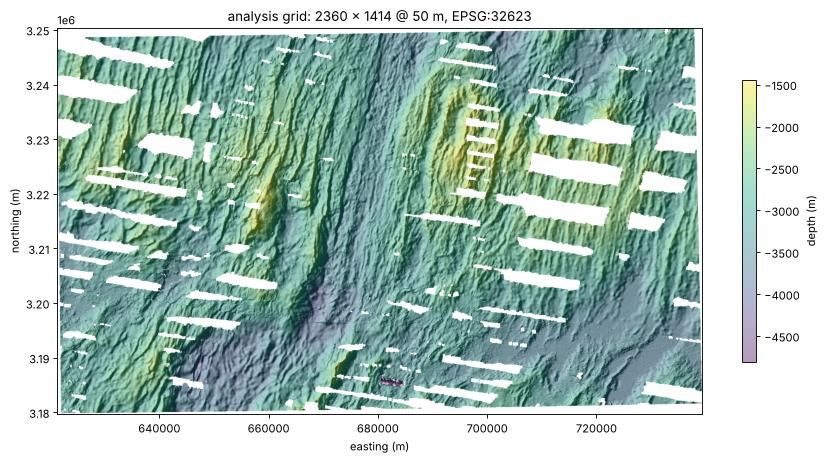

In [6]:
MIN_ISLAND_KM2 = 1.0       # 小于此面积的孤立数据块删除
DESPIKE_WINDOW_M = 250.0   # 滑动中值窗口
DESPIKE_K = 6.0            # |z - 中值| > K 倍稳健 sigma ...
DESPIKE_MIN_M = 25.0       # ... 且 > 25 m 视为尖峰
MAX_HOLE_KM2 = 0.05        # 小于此面积的空洞插值补上

z_c = dem_proj.astype(np.float64)
valid_c = np.isfinite(z_c)
px_km2 = PX * PX / 1e6
# 1) 孤立小数据块
lab, n_lab = ndi.label(valid_c, structure=np.ones((3, 3)))
sizes = ndi.sum(valid_c, lab, np.arange(1, n_lab + 1)) * px_km2
small = np.zeros(n_lab + 1, bool)
small[1:] = sizes < MIN_ISLAND_KM2
valid_c &= ~small[lab]
n_islands = int(small.sum())
# 2) 去尖峰
win = max(3, int(round(DESPIKE_WINDOW_M / PX)) | 1)
_, (ri_c, ci_c) = ndi.distance_transform_edt(~valid_c, return_indices=True)
med = ndi.median_filter(z_c[ri_c, ci_c], size=win)
resid = (z_c - med)[valid_c]
robust_sigma = 1.4826 * np.median(np.abs(resid - np.median(resid)))
spikes = valid_c & (np.abs(z_c - med) > max(DESPIKE_K * robust_sigma, DESPIKE_MIN_M))
valid_c &= ~spikes
# 3) 补小洞（不碰边界的 NaN 连通块），由小到大的高斯尺度做考虑空洞的插值
lab, n_lab = ndi.label(~valid_c, structure=np.ones((3, 3)))
sizes = ndi.sum(~valid_c, lab, np.arange(1, n_lab + 1)) * px_km2
border = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
small = np.zeros(n_lab + 1, bool)
small[1:] = sizes < MAX_HOLE_KM2
small[border] = False
holes = small[lab]
z_filled = np.where(valid_c, z_c, 0.0)
todo = holes.copy()
for sig in (1.0, 2.0, 4.0, 8.0, 16.0):
    num = ndi.gaussian_filter(np.where(valid_c, z_c, 0.0), sig)
    den = ndi.gaussian_filter(valid_c.astype(float), sig)
    ok = todo & (den > 0.05)
    z_filled[ok] = num[ok] / den[ok]
    todo &= ~ok
    if not todo.any():
        break
filled = holes & ~todo
valid_c |= filled
DEM = np.where(valid_c, z_filled, np.nan).astype(np.float32)
EXTENT = (X0 - PX / 2, X0 + (NX - 0.5) * PX, Y0 - (NY - 0.5) * PX, Y0 + PX / 2)
print(f"去掉 {n_islands} 个孤立块、{int(spikes.sum())} 个尖峰，补了 {int(filled.sum())} 个像元；有效像元 {np.isfinite(DEM).mean():.1%}")

# 山体阴影（只用于显示）
_, (ri_h, ci_h) = ndi.distance_transform_edt(~np.isfinite(DEM), return_indices=True)
d_row, d_col = np.gradient(DEM[ri_h, ci_h].astype(np.float64))
hx, hy = 2.0 * d_col / PX, -2.0 * d_row / PX
az_l, alt_l = np.radians(300.0), np.radians(40.0)
HILLSHADE = np.clip((-hx * np.sin(az_l) * np.cos(alt_l) - hy * np.cos(az_l) * np.cos(alt_l) + np.sin(alt_l))
                    / np.sqrt(1 + hx ** 2 + hy ** 2), 0, 1)
HILLSHADE[~np.isfinite(DEM)] = np.nan
fig, ax = plt.subplots(figsize=(13, 13 * NY / NX * 0.85 + 1))
ax.imshow(HILLSHADE, cmap="gray", extent=EXTENT)
im = ax.imshow(DEM, cmap="viridis", alpha=0.4, extent=EXTENT)
fig.colorbar(im, ax=ax, shrink=0.6, label="depth (m)")
ax.set_title(f"analysis grid: {NX} x {NY} @ {PX:.0f} m, EPSG:{EPSG}")
ax.set_xlabel("easting (m)")
ax.set_ylabel("northing (m)")
plt.show()

---
## 5. 数据特征

* **Welch 功率谱**：在全有效的 128×128 窗口上计算；在 1–4 km 波段拟合幂律，**有效分辨率**定义为实测功率降到幂律一半时对应的波长。
* **白噪声**：3×3 中值残差的稳健标准差。
* **纹理方向**：坡度不低于中位数的像元，按 tan²(坡度) 加权，对走向做倍角统计，得到主走向和包含 80% 权重的半宽。

In [7]:
z_d = DEM.astype(float)
valid_dem = np.isfinite(z_d)
# Welch 功率谱（全有效窗口，去平面）
for T in (128, 96, 64, 48, 32):
    acc, n_t = None, 0
    win = np.outer(np.hanning(T), np.hanning(T))
    yy_, xx_ = np.mgrid[:T, :T]
    A_ = np.column_stack([np.ones(T * T), xx_.ravel(), yy_.ravel()])
    for r0 in range(0, NY - T + 1, T // 2):
        for c0 in range(0, NX - T + 1, T // 2):
            if not valid_dem[r0:r0 + T, c0:c0 + T].all():
                continue
            blk = z_d[r0:r0 + T, c0:c0 + T]
            coef_, *_ = np.linalg.lstsq(A_, blk.ravel(), rcond=None)
            blk = blk - (A_ @ coef_).reshape(T, T)
            P_ = np.abs(np.fft.fft2(blk * win)) ** 2 * PX * PX / (win ** 2).sum()
            acc = P_ if acc is None else acc + P_
            n_t += 1
    if n_t >= 8:
        break
P_mean = acc / n_t
kf = np.fft.fftfreq(T, PX)
K_ = np.hypot(*np.meshgrid(kf, kf))
k_edges = np.logspace(np.log10(1.0 / (T * PX)), np.log10(0.5 / PX), 30)
spec_k, spec_p = [], []
for ka, kb in zip(k_edges[:-1], k_edges[1:]):
    m_ = (K_ >= ka) & (K_ < kb)
    if m_.any():
        spec_k.append(np.sqrt(ka * kb))
        spec_p.append(P_mean[m_].mean())
spec_k, spec_p = np.array(spec_k), np.array(spec_p)
lam = 1.0 / spec_k
band = (lam >= 1000.0) & (lam <= 4000.0)
fit_b, fit_a = np.polyfit(np.log10(spec_k[band]), np.log10(spec_p[band]), 1)
ratio = spec_p / 10 ** (fit_a + fit_b * np.log10(spec_k))
LAMBDA_EFF = float(lam.min())
for i_ in np.argsort(-lam):
    if lam[i_] < 1000.0 and ratio[i_] < 0.5:
        LAMBDA_EFF = float(lam[i_])
        break
BETA = float(-fit_b)
# 白噪声
core2 = ndi.binary_erosion(valid_dem, iterations=2)
_, (ri_, ci_) = ndi.distance_transform_edt(~valid_dem, return_indices=True)
zf_d = z_d[ri_, ci_]
resid = (zf_d - ndi.median_filter(zf_d, 3))[core2]
NOISE_M = float(1.4826 * np.median(np.abs(resid - np.median(resid))))
print(f"{n_t} 个 {T}x{T} 窗口；谱指数 beta = {BETA:.2f}；有效分辨率 ≈ {LAMBDA_EFF:.0f} m（节点 {PX:.0f} m）；白噪声 {NOISE_M:.2f} m")

139 个 128x128 窗口；谱指数 beta = 3.80；有效分辨率 ≈ 601 m（节点 50 m）；白噪声 0.00 m


纹理走向 22.0°，80% 权重半宽 45.1° -> 方向容差 45.0°
坡度百分位： {10: 3.2, 25: 6.2, 30: 7.1, 50: 10.9, 75: 17.2, 90: 23.9, 95: 28.3, 99: 37.2}


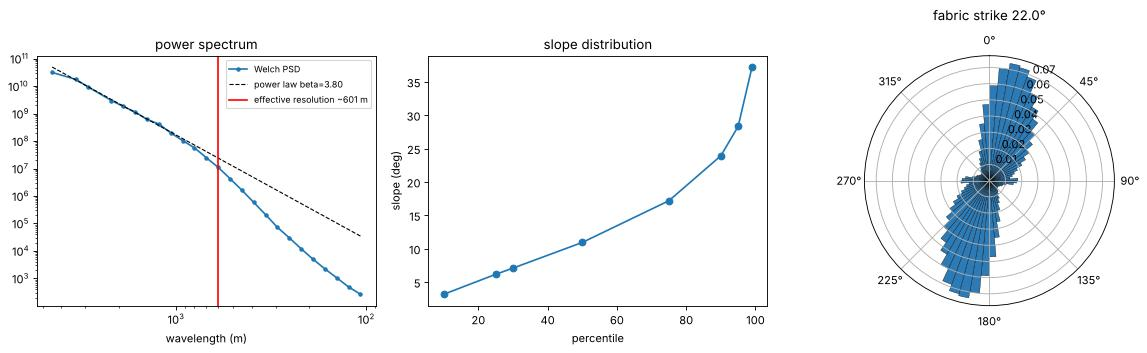

In [8]:
# 节点尺度上的坡度与纹理方向
gx_p = ndi.gaussian_filter(zf_d, 1.0, order=(0, 1), mode="nearest") / PX
gy_p = -ndi.gaussian_filter(zf_d, 1.0, order=(1, 0), mode="nearest") / PX
sl_p = np.degrees(np.arctan(np.hypot(gx_p, gy_p)))
SLOPE_PCT = {q: float(np.percentile(sl_p[core2], q)) for q in (10, 25, 30, 50, 75, 90, 95, 99)}
sel_o = core2 & (sl_p >= np.percentile(sl_p[core2], 50))
strike_px = (np.degrees(np.arctan2(-gx_p[sel_o], -gy_p[sel_o])) % 360.0 + 90.0) % 180.0
w_o = np.tan(np.radians(sl_p[sel_o])) ** 2
C_, S_ = np.sum(w_o * np.cos(np.radians(2 * strike_px))), np.sum(w_o * np.sin(np.radians(2 * strike_px)))
FABRIC_STRIKE = float(np.degrees(np.arctan2(S_, C_)) / 2 % 180.0)
dev_o = np.abs((strike_px - FABRIC_STRIKE) % 180.0)
dev_o = np.minimum(dev_o, 180.0 - dev_o)
ord_o = np.argsort(dev_o)
TOL80 = float(dev_o[ord_o][np.searchsorted(np.cumsum(w_o[ord_o]) / w_o.sum(), 0.8)])
ORIENT_TOL = float(np.clip(TOL80, 20.0, 45.0))
print(f"纹理走向 {FABRIC_STRIKE:.1f}°，80% 权重半宽 {TOL80:.1f}° -> 方向容差 {ORIENT_TOL:.1f}°")
print("坡度百分位：", {q: round(v, 1) for q, v in SLOPE_PCT.items()})

fig = plt.figure(figsize=(15, 4.5))
ax = fig.add_subplot(1, 3, 1)
ax.loglog(lam, spec_p, "o-", ms=3, label="Welch PSD")
ax.loglog(lam, 10 ** (fit_a + fit_b * np.log10(spec_k)), "k--", lw=1, label=f"power law beta={BETA:.2f}")
ax.axvline(LAMBDA_EFF, color="r", label=f"effective resolution ~{LAMBDA_EFF:.0f} m")
ax.invert_xaxis()
ax.set_xlabel("wavelength (m)")
ax.legend(fontsize=8)
ax.set_title("power spectrum")
ax = fig.add_subplot(1, 3, 2)
ax.plot(list(SLOPE_PCT), list(SLOPE_PCT.values()), "o-")
ax.set_xlabel("percentile")
ax.set_ylabel("slope (deg)")
ax.set_title("slope distribution")
ax = fig.add_subplot(1, 3, 3, projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
h_, e_ = np.histogram(strike_px, bins=36, range=(0, 180), weights=w_o)
ax.bar(np.radians(np.concatenate([e_[:-1], e_[:-1] + 180])), np.concatenate([h_, h_]) / h_.sum(),
       width=np.radians(5), align="edge", color="#2c7bb6", edgecolor="k", lw=0.3)
ax.set_title(f"fabric strike {FABRIC_STRIKE:.1f}°", pad=12)
plt.tight_layout()
plt.show()

## 6. 尺度选择

在候选尺度上，提取陡坎脊线的坡度（沿梯度方向的坡度极大值，且方向在容差内），对 log tan(坡度) 拟合**双高斯混合**（EM 算法），用 **Ashman D** 衡量"背景"和"陡坎"两类分得有多开，取 D 最大的尺度。
尺度的下限由白噪声决定：要保证坡度噪声小于 1°。

In [9]:
sig_noise_px = np.sqrt(max(NOISE_M, 1e-6) / (2 * np.sqrt(2 * np.pi) * np.tan(np.radians(1.0)) * PX))
scale_table = []
for s_px in (1.0, 1.5, 2.0, 3.0):
    if s_px < sig_noise_px:
        continue
    sigma_m = s_px * PX
    gx_s = ndi.gaussian_filter(zf_d, s_px, order=(0, 1), mode="nearest") / PX
    gy_s = -ndi.gaussian_filter(zf_d, s_px, order=(1, 0), mode="nearest") / PX
    sl_s = np.degrees(np.arctan(np.hypot(gx_s, gy_s)))
    fa_s = np.degrees(np.arctan2(-gx_s, -gy_s)) % 360.0
    gc_, gr_ = gx_s * PX, -gy_s * PX
    gnm = np.hypot(gc_, gr_)
    gnm[gnm == 0] = 1e-12
    rr_i, cc_i = np.indices(sl_s.shape, dtype=np.float64)
    m1 = ndi.map_coordinates(sl_s, [rr_i + gr_ / gnm, cc_i + gc_ / gnm], order=1, mode="nearest")
    m2 = ndi.map_coordinates(sl_s, [rr_i - gr_ / gnm, cc_i - gc_ / gnm], order=1, mode="nearest")
    core_s = ndi.binary_erosion(valid_dem, iterations=max(2, int(round(2 * sigma_m / PX))))
    dv_ = np.abs((fa_s - (FABRIC_STRIKE + 90.0)) % 180.0)
    ridge = (sl_s >= m1) & (sl_s >= m2) & core_s & (np.minimum(dv_, 180.0 - dv_) <= ORIENT_TOL) & (sl_s >= 0.5)
    y_ = np.log(np.tan(np.radians(sl_s[ridge])))
    # 双高斯混合（EM）
    mu = np.percentile(y_, [25, 75]).astype(float)
    sd = np.array([y_.std() / 2, y_.std() / 2]) + 1e-6
    wt = np.array([0.5, 0.5])
    ll_old = -np.inf
    for _ in range(300):
        pdf = wt / (sd * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((y_[:, None] - mu) / sd) ** 2)
        tot = pdf.sum(axis=1) + 1e-300
        resp_ = pdf / tot[:, None]
        nk = resp_.sum(axis=0) + 1e-12
        wt = nk / y_.size
        mu = (resp_ * y_[:, None]).sum(axis=0) / nk
        sd = np.sqrt((resp_ * (y_[:, None] - mu) ** 2).sum(axis=0) / nk) + 1e-6
        ll = np.log(tot).sum()
        if ll - ll_old < 1e-8 * abs(ll):
            break
        ll_old = ll
    o_ = np.argsort(mu)
    wt, mu, sd = wt[o_], mu[o_], sd[o_]
    ashman = float(np.sqrt(2) * abs(mu[1] - mu[0]) / np.sqrt(sd[0] ** 2 + sd[1] ** 2))
    scale_table.append({"sigma_m": sigma_m, "ashman_d": ashman, "n_ridge": int(y_.size),
                        "gmm": (wt.copy(), mu.copy(), sd.copy()), "ridge_slopes": sl_s[ridge],
                        "slope_p30": float(np.percentile(sl_s[core_s], 30))})
    print(f"sigma = {sigma_m:5.0f} m：{y_.size} 个脊线像元，Ashman D = {ashman:.3f}")
best_scale = scale_table[int(np.argmax([r_["ashman_d"] for r_ in scale_table]))]
SIGMA_SEL = best_scale["sigma_m"]
print(f"-> 选定尺度 SIGMA_M = {SIGMA_SEL:.0f} m")

sigma =    50 m：247603 个脊线像元，Ashman D = 1.464


sigma =    75 m：213485 个脊线像元，Ashman D = 1.499


sigma =   100 m：187305 个脊线像元，Ashman D = 1.486


sigma =   150 m：148428 个脊线像元，Ashman D = 1.385
-> 选定尺度 SIGMA_M = 75 m


## 7. 坡度阈值

在选定尺度上：`slope_high` 取混合模型后验 P(陡坎) = 0.9 处的坡度，`slope_low` 取 0.5 处，`stop_slope` 取全部坡度的第 30 百分位（"平坦"地形）。
另有一些随网格换算的设置：边缘缓冲 = max(2 像元, 2σ)，简化容差 = max(0.6 像元, 30 m)，最短候选 = max(300 m, 6 像元)。

背景 5.9°，陡坎 17.0° -> slope_high 12.35°，slope_low 8.82°，stop 6.82°


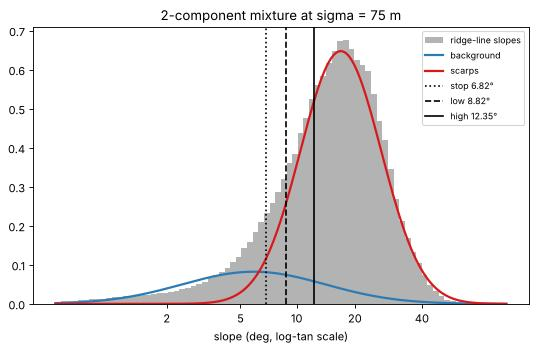

In [10]:
wt, mu, sd = best_scale["gmm"]
xs_g = np.linspace(-4.0, 1.0, 4001)
pdf_g = wt / (sd * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((xs_g[:, None] - mu) / sd) ** 2)
post = pdf_g[:, 1] / pdf_g.sum(axis=1)
start = np.searchsorted(xs_g, mu[0])
hi_idx = np.nonzero(post[start:] >= 0.9)[0]
lo_idx = np.nonzero(post[start:] >= 0.5)[0]
x_hi = xs_g[start + hi_idx[0]] if hi_idx.size else mu[1]
x_lo = xs_g[start + lo_idx[0]] if lo_idx.size else mu[1]
stop_sel = float(np.clip(best_scale["slope_p30"], 2.0, 10.0))
low_sel = max(float(np.degrees(np.arctan(np.exp(x_lo)))), stop_sel + 2.0)
high_sel = max(float(np.degrees(np.arctan(np.exp(x_hi)))), low_sel + 2.0)
SLOPE_HIGH_SEL, SLOPE_LOW_SEL, STOP_SLOPE_SEL = round(high_sel, 2), round(low_sel, 2), round(stop_sel, 2)
EDGE_BUFFER_SEL = max(2 * PX, 2 * SIGMA_SEL)
SIMPLIFY_SEL = max(0.6 * PX, 30.0)
MIN_CANDIDATE_SEL = max(300.0, 6 * PX)
print(f"背景 {np.degrees(np.arctan(np.exp(mu[0]))):.1f}°，陡坎 {np.degrees(np.arctan(np.exp(mu[1]))):.1f}° "
      f"-> slope_high {SLOPE_HIGH_SEL}°，slope_low {SLOPE_LOW_SEL}°，stop {STOP_SLOPE_SEL}°")

ys_ = np.log(np.tan(np.radians(np.clip(best_scale["ridge_slopes"], 0.5, 80))))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(ys_, bins=80, density=True, color="0.7", label="ridge-line slopes")
xx_g = np.linspace(ys_.min(), ys_.max(), 400)
for kc, col, lab in ((0, "#2c7bb6", "background"), (1, "#d7191c", "scarps")):
    ax.plot(xx_g, wt[kc] / (sd[kc] * np.sqrt(2 * np.pi)) * np.exp(-0.5 * ((xx_g - mu[kc]) / sd[kc]) ** 2),
            color=col, lw=2, label=lab)
for val, lab, ls in ((STOP_SLOPE_SEL, "stop", ":"), (SLOPE_LOW_SEL, "low", "--"), (SLOPE_HIGH_SEL, "high", "-")):
    ax.axvline(np.log(np.tan(np.radians(val))), color="k", ls=ls, label=f"{lab} {val}°")
ax.set_xticks(np.log(np.tan(np.radians([2, 5, 10, 20, 40]))))
ax.set_xticklabels(["2", "5", "10", "20", "40"])
ax.set_xlabel("slope (deg, log-tan scale)")
ax.legend(fontsize=8)
ax.set_title(f"2-component mixture at sigma = {SIGMA_SEL:.0f} m")
plt.show()

## 8. 零假设：相位随机化替代地形

替代地形保留真实网格的二维功率谱（起伏、粗糙度、各向异性纹理都不变），但随机化傅里叶相位，因此没有相干的台阶状陡坎。
在替代地形上检测到的都是误报（decoy）。

做法：先用高斯插值把空洞补平滑，去平面趋势，镜像延拓成周期场，做 FFT，换成随机相位后逆变换，把标准差缩放回原值，最后加回趋势并套用原来的空洞掩膜。

替代地形 1/4 已生成


替代地形 2/4 已生成


替代地形 3/4 已生成


替代地形 4/4 已生成


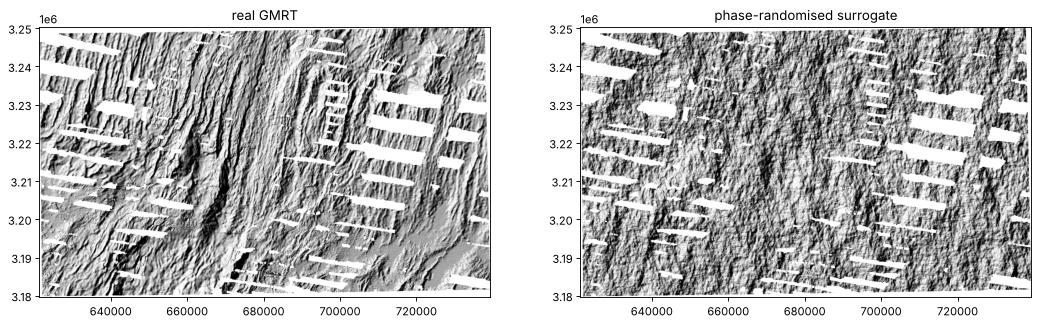

In [11]:
rng = np.random.default_rng(SEED)
surrogates = []
for k_s in range(N_SURROGATES):
    out_ = np.where(valid_dem, DEM, 0.0).astype(float)      # 空洞用平滑插值补上（在 float32 的 DEM 上做）
    todo_ = ~valid_dem
    for sg in (2, 4, 8, 16, 32, 64, 128):
        if not todo_.any():
            break
        num_ = ndi.gaussian_filter(np.where(valid_dem, DEM, 0.0), sg)
        den_ = ndi.gaussian_filter(valid_dem.astype(float), sg)
        ok_ = todo_ & (den_ > 1e-3)
        out_[ok_] = num_[ok_] / den_[ok_]
        todo_ &= ~ok_
    if todo_.any():
        out_[todo_] = np.nanmean(DEM[valid_dem])
    yy_, xx_ = np.mgrid[:NY, :NX]
    A_ = np.column_stack([np.ones(NY * NX), xx_.ravel(), yy_.ravel()])
    coef_, *_ = np.linalg.lstsq(A_[valid_dem.ravel()], out_[valid_dem], rcond=None)
    trend = (A_ @ coef_).reshape(NY, NX)
    dtr = out_ - trend
    ext = np.block([[dtr, dtr[:, ::-1]], [dtr[::-1, :], dtr[::-1, ::-1]]])
    phase = np.angle(np.fft.fft2(rng.standard_normal(ext.shape)))
    s_ = np.real(np.fft.ifft2(np.abs(np.fft.fft2(ext)) * np.exp(1j * phase)))[:NY, :NX]
    s_ *= dtr[valid_dem].std() / max(s_[valid_dem].std(), 1e-12)
    sur = s_ + trend
    sur[~valid_dem] = np.nan
    surrogates.append(sur.astype(np.float32))
    print(f"替代地形 {k_s + 1}/{N_SURROGATES} 已生成")
del A_, yy_, xx_, ext

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
for ax, zz_, ttl in ((axs[0], DEM, "real GMRT"), (axs[1], surrogates[0], "phase-randomised surrogate")):
    _, (ri_, ci_) = ndi.distance_transform_edt(~np.isfinite(zz_), return_indices=True)
    dr_, dc_ = np.gradient(zz_[ri_, ci_].astype(float))
    hx_, hy_ = 2 * dc_ / PX, -2 * dr_ / PX
    hs_ = np.clip((-hx_ * np.sin(az_l) * np.cos(alt_l) - hy_ * np.cos(az_l) * np.cos(alt_l) + np.sin(alt_l))
                  / np.sqrt(1 + hx_ ** 2 + hy_ ** 2), 0, 1)
    hs_[~np.isfinite(zz_)] = np.nan
    ax.imshow(hs_, cmap="gray", extent=EXTENT)
    ax.set_title(ttl)
plt.show()

## 9. 在真实网格和替代地形上运行识别流水线

下面循环里的代码，和实现笔记本第 6–13 步**完全相同**，依次作用于以下网格：

| 名称 | 网格 | 参数 | 用途 |
|---|---|---|---|
| `real` | 真实 GMRT | 第 6–7 步得到的参数，走向固定为纹理走向 | 和替代地形对照 |
| `sur1…sur4` | 替代地形 | 同上 | 误报（decoy） |
| `real_auto` | 真实 GMRT | 同上，但走向自动估计 | 与实现笔记本的运行方式完全一致，用于第 15 步 |
| `real_ref` | 真实 GMRT | 为 CD99 100 m 网格手调的参考参数 | 对照，用于第 15 步 |

In [12]:
REL_STOP, RISE_TOL_DEG, MAX_WALK_M, MIN_PIXEL_THROW_M = 0.25, 2.0, 2000.0, 20.0     # 固定常数
LINK_GAP_M, LINK_ANGLE_DEG = 500.0, 25.0
P_SEL = {"sigma": SIGMA_SEL, "tol": ORIENT_TOL, "high": SLOPE_HIGH_SEL, "low": SLOPE_LOW_SEL,
         "stop": STOP_SLOPE_SEL, "edge": EDGE_BUFFER_SEL, "simplify": SIMPLIFY_SEL, "min_cand": MIN_CANDIDATE_SEL}
P_REF = {"sigma": 100.0, "tol": 35.0, "high": 18.0, "low": 10.0, "stop": 6.0, "edge": 200.0,
         "simplify": 60.0, "min_cand": 300.0}                                             # CD99 手调参数
scan = [("real", DEM, P_SEL, FABRIC_STRIKE)]
scan += [(f"sur{k + 1}", surrogates[k], P_SEL, FABRIC_STRIKE) for k in range(N_SURROGATES)]
scan += [("real_auto", DEM, P_SEL, None), ("real_ref", DEM, P_REF, None)]
all_candidates, all_strike = {}, {}

In [13]:
t_scan = time.time()
for scan_name, Z_IN, P_, STRIKE_FIXED in scan:
    SIGMA_M, ORIENT_TOL_DEG, SLOPE_HIGH_DEG, SLOPE_LOW_DEG = P_["sigma"], P_["tol"], P_["high"], P_["low"]
    STOP_SLOPE_DEG, EDGE_BUFFER_M, SIMPLIFY_TOL_M, MIN_CANDIDATE_M = P_["stop"], P_["edge"], P_["simplify"], P_["min_cand"]
    sigma_px = SIGMA_M / PX
    v_in = np.isfinite(Z_IN)
    _, (ri_, ci_) = ndi.distance_transform_edt(~v_in, return_indices=True)
    zf = Z_IN[ri_, ci_].astype(np.float64)
    zs = ndi.gaussian_filter(zf, sigma_px, mode="nearest")
    gx = ndi.gaussian_filter(zf, sigma_px, order=(0, 1), mode="nearest") / PX     # dz/d(东)
    gy = -ndi.gaussian_filter(zf, sigma_px, order=(1, 0), mode="nearest") / PX    # dz/d(北)
    slope = np.degrees(np.arctan(np.hypot(gx, gy)))
    facing = np.degrees(np.arctan2(-gx, -gy)) % 360.0                             # 下坡方位 = 陡坎朝向
    buf_px = int(round(EDGE_BUFFER_M / PX))
    core_in = ndi.binary_erosion(v_in, iterations=buf_px) if buf_px > 0 else v_in
    if STRIKE_FIXED is None:                                                       # 结构张量求区域走向
        sel_ = core_in & np.isfinite(gx) & np.isfinite(gy) & (slope >= 5.0)
        jxx, jyy, jxy = np.sum(gx[sel_] ** 2), np.sum(gy[sel_] ** 2), np.sum(gx[sel_] * gy[sel_])
        phi_ = 0.5 * np.arctan2(2 * jxy, jxx - jyy)
        STRIKE = float(((90.0 - np.degrees(phi_)) % 180.0 + 90.0) % 180.0)
    else:
        STRIKE = float(STRIKE_FIXED) % 180.0
    g_col, g_row = gx * PX, -gy * PX                       # 像元坐标系中的梯度
    g_nrm = np.hypot(g_col, g_row)
    g_nrm[g_nrm == 0] = 1e-12
    rr_i, cc_i = np.indices(slope.shape, dtype=np.float64)
    m1 = ndi.map_coordinates(slope, [rr_i + g_row / g_nrm, cc_i + g_col / g_nrm], order=1, mode="nearest")
    m2 = ndi.map_coordinates(slope, [rr_i - g_row / g_nrm, cc_i - g_col / g_nrm], order=1, mode="nearest")
    nms = (slope >= m1) & (slope >= m2)                    # 沿梯度方向的坡度极大值 = 陡坎中心线
    dev_ = np.abs((facing - (STRIKE + 90.0)) % 180.0)
    orient_ok = np.minimum(dev_, 180.0 - dev_) <= ORIENT_TOL_DEG
    cand_px = nms & orient_ok & core_in & (slope >= SLOPE_LOW_DEG)
    edges = apply_hysteresis_threshold(np.where(cand_px, slope, 0.0), SLOPE_LOW_DEG, SLOPE_HIGH_DEG)
    del rr_i, cc_i, m1, m2
    er, ec = np.nonzero(edges)
    w_rows, w_cols = er.astype(float), ec.astype(float)
    n_e = w_rows.size
    H_, W_ = zs.shape
    ge = ndi.map_coordinates(gx, [w_rows, w_cols], order=1, mode="nearest")
    gn = ndi.map_coordinates(gy, [w_rows, w_cols], order=1, mode="nearest")
    g_abs = np.hypot(ge, gn)
    g_abs[g_abs == 0] = 1e-12
    ue, un = ge / g_abs, gn / g_abs                        # 上坡方向的单位向量（东、北）
    t_stop = np.maximum(np.tan(np.radians(STOP_SLOPE_DEG)), REL_STOP * g_abs)
    step_m = 0.5 * PX
    n_steps = int(np.ceil(MAX_WALK_M / step_m))
    v_f = v_in.astype(float)
    truncated = np.zeros(n_e, bool)
    walk = {}
    for sign, side_name in ((1, "up"), (-1, "down")):
        d_out = np.full(n_e, MAX_WALK_M)
        active = np.ones(n_e, bool)
        run_min = g_abs.copy()                             # 途中遇到的最小沿倾向坡度
        run_min_d = np.zeros(n_e)
        for k in range(1, n_steps + 1):
            ix = np.nonzero(active)[0]
            if ix.size == 0:
                break
            d_m = k * step_m
            rr = w_rows[ix] - sign * d_m * un[ix] / PX
            cc = w_cols[ix] + sign * d_m * ue[ix] / PX
            inside = (rr >= 0) & (rr <= H_ - 1) & (cc >= 0) & (cc <= W_ - 1)
            se = ndi.map_coordinates(gx, [rr, cc], order=1, mode="nearest")
            sn = ndi.map_coordinates(gy, [rr, cc], order=1, mode="nearest")
            dd = se * ue[ix] + sn * un[ix]                 # 沿倾向坡度
            gap = ~inside | (ndi.map_coordinates(v_f, [rr, cc], order=1, mode="constant", cval=0) < 0.5)
            brk = dd < t_stop[ix]                          # 到达坡折
            rise = (np.degrees(np.arctan(dd)) - np.degrees(np.arctan(run_min[ix]))) > RISE_TOL_DEG   # 进入下一条陡坎
            stop = brk | gap | rise
            d_end = np.where(rise & ~brk, run_min_d[ix], d_m - 0.5 * step_m)
            d_out[ix[stop]] = d_end[stop]
            truncated[ix[gap & ~brk & ~rise]] = True
            lower = dd < run_min[ix]
            run_min[ix[lower]] = dd[lower]
            run_min_d[ix[lower]] = d_m
            active[ix[stop]] = False
        truncated[active] = True
        walk[side_name] = d_out
    z_top = ndi.map_coordinates(zs, [w_rows - walk["up"] * un / PX, w_cols + walk["up"] * ue / PX], order=1, mode="nearest")
    z_bot = ndi.map_coordinates(zs, [w_rows + walk["down"] * un / PX, w_cols - walk["down"] * ue / PX], order=1, mode="nearest")
    e_throw = z_top - z_bot                                # 断距
    e_width = walk["up"] + walk["down"]                    # 陡坎水平宽度
    e_facing = np.degrees(np.arctan2(-ge, -gn)) % 360.0
    keep_e = e_throw >= MIN_PIXEL_THROW_M
    throw_map = np.full(Z_IN.shape, np.nan, np.float32)
    width_map = np.full(Z_IN.shape, np.nan, np.float32)
    facing_map = np.full(Z_IN.shape, np.nan, np.float32)
    trunc_map = np.zeros(Z_IN.shape, bool)
    throw_map[er[keep_e], ec[keep_e]] = e_throw[keep_e]
    width_map[er[keep_e], ec[keep_e]] = e_width[keep_e]
    facing_map[er[keep_e], ec[keep_e]] = e_facing[keep_e]
    trunc_map[er[keep_e], ec[keep_e]] = truncated[keep_e]
    scarp_mask = np.zeros(Z_IN.shape, bool)
    scarp_mask[er[keep_e], ec[keep_e]] = True
    skel = skeletonize(scarp_mask)
    OFFS = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
    sk_r, sk_c = np.nonzero(skel)
    idx_map = -np.ones(skel.shape, dtype=np.int64)
    idx_map[sk_r, sk_c] = np.arange(sk_r.size)
    adj = [[] for _ in range(sk_r.size)]
    H_, W_ = skel.shape
    for kp in range(sk_r.size):
        r_, c_ = sk_r[kp], sk_c[kp]
        for dr, dc in OFFS:
            r2, c2 = r_ + dr, c_ + dc
            if not (0 <= r2 < H_ and 0 <= c2 < W_):
                continue
            j_ = idx_map[r2, c2]
            if j_ < 0:
                continue
            if dr != 0 and dc != 0 and (skel[r_, c2] or skel[r2, c_]):   # 有 4 邻接绕行时去掉对角连接
                continue
            adj[kp].append(int(j_))
    deg = np.array([len(a_) for a_ in adj])
    used = set()
    paths = []
    for phase in (0, 1):            # 0：从端点 / 交点出发；1：剩下的闭环
        for v0 in range(sk_r.size):
            if (phase == 0) == (deg[v0] == 2):
                continue
            for w0 in adj[v0]:
                if (min(v0, w0), max(v0, w0)) in used:
                    continue
                path = [v0]
                prev, cur = v0, w0
                used.add((min(v0, w0), max(v0, w0)))
                while True:
                    path.append(cur)
                    if deg[cur] != 2:
                        break
                    nxt = [w_ for w_ in adj[cur] if w_ != prev and (min(cur, w_), max(cur, w_)) not in used]
                    if not nxt:
                        break
                    prev, cur = cur, nxt[0]
                    used.add((min(prev, cur), max(prev, cur)))
                if len(path) >= 3:
                    paths.append(np.column_stack([sk_r[path], sk_c[path]]))
    side_e, side_n = np.sin(np.radians(STRIKE + 90.0)), np.cos(np.radians(STRIKE + 90.0))
    fac_rad = np.radians(np.nan_to_num(facing_map))
    side_map = np.where(np.sin(fac_rad) * side_e + np.cos(fac_rad) * side_n >= 0, 1, -1)   # +1 = 朝向走向+90°一侧
    segs, seg_pix, seg_side = [], [], []
    for pth in paths:
        pr, pc = pth[:, 0], pth[:, 1]
        ok_ = np.isfinite(facing_map[pr, pc])
        if ok_.sum() < 3:
            continue
        pr, pc = pr[ok_], pc[ok_]
        cuts = np.nonzero(np.diff(side_map[pr, pc]) != 0)[0] + 1      # 朝向翻转处断开
        for s_r, s_c in zip(np.split(pr, cuts), np.split(pc, cuts)):
            if s_r.size < 3:
                continue
            segs.append(np.column_stack([X0 + s_c * PX, Y0 - s_r * PX]))
            seg_pix.append((s_r, s_c))
            seg_side.append(int(side_map[s_r[0], s_c[0]]))
    lines_in = []                                          # 三点滑动平均，端点不动
    for s_ in segs:
        if len(s_) <= 2:
            lines_in.append(np.asarray(s_, float))
            continue
        sm_ = s_.astype(float).copy()
        for dim in range(2):
            padded = np.pad(s_[:, dim].astype(float), 1, mode="edge")
            sm_[:, dim] = np.convolve(padded, np.ones(3) / 3, mode="valid")[: len(s_)]
        sm_[0], sm_[-1] = s_[0], s_[-1]
        lines_in.append(sm_)
    SPAN = 2.0 * LINK_GAP_M
    COS_MAX = np.cos(np.radians(LINK_ANGLE_DEG))
    MAX_OFF = 0.6 * LINK_GAP_M
    n_l = len(lines_in)
    ends, info, tang = [], [], []
    for i_l, l_ in enumerate(lines_in):
        if len(l_) < 2:
            continue
        for at_start in (True, False):
            pts_ = l_[::-1] if at_start else l_            # pts_[-1] 就是这个端点
            rev_ = pts_[::-1]
            cum_ = np.concatenate([[0], np.cumsum(np.hypot(*np.diff(rev_, axis=0).T))])
            kk = min(max(int(np.searchsorted(cum_, SPAN)), 1), len(pts_) - 1)
            tv = pts_[-1] - rev_[kk]
            tn = np.hypot(*tv)
            ends.append(pts_[-1])
            info.append((i_l, at_start))
            tang.append(tv / tn if tn > 0 else np.array([0.0, 0.0]))   # 指向线外的端点切向
    end_id = {key: k for k, key in enumerate(info)}
    link = {}
    if len(ends) >= 2:
        ends_arr = np.array(ends)
        pairs = []
        for a_, b_ in cKDTree(ends_arr).query_pairs(LINK_GAP_M):
            (i_a, _), (i_b, _) = info[a_], info[b_]
            if i_a == i_b or seg_side[i_a] != seg_side[i_b]:
                continue
            ta, tb = tang[a_], tang[b_]
            gv = ends_arr[b_] - ends_arr[a_]
            gl = float(np.hypot(*gv))
            if gl > 0:
                gu = gv / gl
                if ta @ gu < COS_MAX or -(tb @ gu) < COS_MAX:
                    continue
                if abs(ta[0] * gv[1] - ta[1] * gv[0]) > MAX_OFF:
                    continue
            if -(ta @ tb) < COS_MAX:
                continue
            pairs.append((gl / LINK_GAP_M + (1 + ta @ tb), a_, b_))
        pairs.sort()
        parent = list(range(n_l))
        for _, a_, b_ in pairs:                            # 代价最小的连接优先，不成环
            if a_ in link or b_ in link:
                continue
            ra = info[a_][0]
            while parent[ra] != ra:
                parent[ra] = parent[parent[ra]]
                ra = parent[ra]
            rb = info[b_][0]
            while parent[rb] != rb:
                parent[rb] = parent[parent[rb]]
                rb = parent[rb]
            if ra == rb:
                continue
            link[a_] = b_
            link[b_] = a_
            parent[ra] = rb
    visited = set()
    linked, groups = [], []
    for i_l in range(n_l):
        if i_l in visited:
            continue
        if len(lines_in[i_l]) < 2:
            visited.add(i_l)
            linked.append(lines_in[i_l])
            groups.append([i_l])
            continue
        cur, free_start, seen = i_l, True, {i_l}
        while True:                                        # 先走到链的一端
            kk = end_id[(cur, free_start)]
            if kk not in link:
                break
            j_, sj = info[link[kk]]
            if j_ in seen:
                break
            seen.add(j_)
            cur, free_start = j_, not sj
        parts, ids = [], []
        entry_start = free_start
        while True:                                        # 再顺着链拼接
            l_ = lines_in[cur]
            parts.append(l_ if entry_start else l_[::-1])
            ids.append(cur)
            visited.add(cur)
            kk = end_id[(cur, not entry_start)]
            if kk not in link:
                break
            j_, sj = info[link[kk]]
            if j_ in visited:
                break
            cur, entry_start = j_, sj
        linked.append(np.vstack(parts))
        groups.append(ids)
    candidates = []
    for line, grp in zip(linked, groups):
        seg_len = np.hypot(*np.diff(line, axis=0).T) if len(line) >= 2 else np.zeros(0)
        length = float(seg_len.sum())
        if length < MIN_CANDIDATE_M:
            continue
        pr = np.concatenate([seg_pix[g][0] for g in grp])
        pc = np.concatenate([seg_pix[g][1] for g in grp])
        thr = throw_map[pr, pc]
        wid = width_map[pr, pc]
        fac = facing_map[pr, pc]
        slp = slope[pr, pc].astype(np.float32)
        trc = trunc_map[pr, pc]
        # Douglas-Peucker 简化
        keep_v = np.zeros(len(line), bool)
        keep_v[0] = keep_v[-1] = True
        stack = [(0, len(line) - 1)] if len(line) >= 3 else []
        while stack:
            i0, i1 = stack.pop()
            if i1 <= i0 + 1:
                continue
            pa, pb = line[i0], line[i1]
            sv = pb - pa
            Ls = np.hypot(*sv)
            mid = line[i0 + 1:i1]
            dpt = (np.hypot(*(mid - pa).T) if Ls == 0
                   else np.abs(sv[0] * (mid[:, 1] - pa[1]) - sv[1] * (mid[:, 0] - pa[0])) / Ls)
            km = int(np.argmax(dpt))
            if dpt[km] > SIMPLIFY_TOL_M:
                keep_v[i0 + 1 + km] = True
                stack.append((i0, i0 + 1 + km))
                stack.append((i0 + 1 + km, i1))
        xy_s = line[keep_v] if len(line) >= 3 else line
        # 主轴走向（等距重采样后的主成分）
        cum = np.concatenate([[0], np.cumsum(seg_len)])
        n_rs = max(int(np.ceil(cum[-1] / max(length / 50, 1e-6))), 1)
        t_rs = np.linspace(0, cum[-1], n_rs + 1)
        rs = np.column_stack([np.interp(t_rs, cum, line[:, 0]), np.interp(t_rs, cum, line[:, 1])])
        cen = rs - rs.mean(axis=0)
        ev, evec = np.linalg.eigh(cen.T @ cen)
        pe, pn = evec[:, np.argmax(ev)]
        strike_c = float(np.degrees(np.arctan2(pe, pn)) % 180.0)
        straight = float(np.hypot(*(line[-1] - line[0])) / length) if length > 0 else 1.0
        fin_t = thr[np.isfinite(thr)]
        fin_w = wid[np.isfinite(wid)]
        med_t = float(np.median(fin_t)) if fin_t.size else 0.0
        q25, q75 = np.percentile(fin_t, [25, 75]) if fin_t.size else (0.0, 0.0)
        med_w = float(np.median(fin_w)) if fin_w.size else 1.0
        fa = np.radians(fac[np.isfinite(fac)])
        R_fac = float(np.hypot(np.mean(np.sin(fa)), np.mean(np.cos(fa)))) if fa.size else 0.0
        sdev = abs((strike_c - STRIKE) % 180.0)
        sdev = min(sdev, 180.0 - sdev)
        fa_all = np.radians(fac)
        candidates.append({
            "xy": xy_s, "pix_xy": np.column_stack([X0 + pc * PX, Y0 - pr * PX]), "pix_throw": thr,
            "length_km": length / 1000.0, "strike_deg": strike_c,
            "facing_az": float(np.degrees(np.arctan2(np.mean(np.sin(fa_all)), np.mean(np.cos(fa_all)))) % 360.0),
            "facing_side": "E" if seg_side[grp[0]] > 0 else "W",
            "throw_median_m": float(np.nanmedian(thr)), "throw_p90_m": float(np.nanpercentile(thr, 90)),
            "scarp_width_median_m": float(np.nanmedian(wid)),
            "scarp_slope_median_deg": float(np.degrees(np.arctan2(np.nanmedian(thr), np.nanmedian(wid)))),
            "straightness": straight, "n_segments": len(grp),
            "features": {
                "log10_length_m": float(np.log10(max(length, 1.0))),
                "log10_throw_m": float(np.log10(max(med_t, 1.0))),
                "throw_iqr_rel": float((q75 - q25) / max(med_t, 1.0)),
                "scarp_slope_deg": float(np.degrees(np.arctan2(med_t, max(med_w, 1.0)))),
                "peak_slope_deg": float(np.nanmedian(slp)) if slp.size else 0.0,
                "log10_width_m": float(np.log10(max(med_w, 1.0))),
                "straightness": straight,
                "strike_dev_deg": float(sdev),
                "facing_consistency": R_fac,
                "truncated_frac": float(np.mean(trc)) if trc.size else 0.0}})
    order_ = np.argsort([-c_["length_km"] for c_ in candidates], kind="stable")
    candidates = [candidates[i] for i in order_]
    all_candidates[scan_name] = candidates
    all_strike[scan_name] = STRIKE
    print(f"[{time.time() - t_scan:5.0f}s] {scan_name:9s} 走向 {STRIKE:5.1f}°：{len(candidates):5d} 条候选，"
          f"总长 {sum(c_['length_km'] for c_ in candidates):6.0f} km")

[    6s] real      走向  22.0°： 4992 条候选，总长   5958 km


[   14s] sur1      走向  22.0°： 6963 条候选，总长   5372 km


[   21s] sur2      走向  22.0°： 7069 条候选，总长   5409 km


[   29s] sur3      走向  22.0°： 6513 条候选，总长   5008 km


[   36s] sur4      走向  22.0°： 6832 条候选，总长   5347 km


[   43s] real_auto 走向  21.9°： 4990 条候选，总长   5958 km


[   47s] real_ref  走向  21.9°： 2433 条候选，总长   2986 km


## 10. 统计标定：target-decoy 错误发现率（FDR）控制

对每一组接受阈值（最短长度 L、最小断距 T、最大走向偏离 D），计算 FDR = 替代地形上保留的平均长度 / 真实网格上保留的长度。
在 FDR ≤ 目标值的组合里，选保留真实长度最多的一组。

真实候选 5958 km，替代地形平均 5284 km
FDR ≤ 0.1：最短 3250 m，最小断距 10 m，走向偏离 ≤ 45° -> 估计 FDR 0.096，保留 1263 km


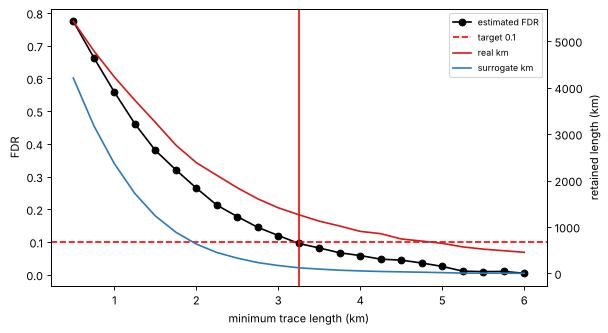

In [14]:
LENGTHS_KM = np.round(np.arange(0.5, 6.01, 0.25), 2)
THROWS_M = np.array([10, 20, 30, 40, 50, 60, 80, 100, 150])
DEVS_DEG = np.array([10, 15, 20, 25, 30, 45, 90])
arr_real = np.array([[c_["length_km"], c_["throw_median_m"], c_["features"]["strike_dev_deg"]] for c_ in all_candidates["real"]])
arr_null = [np.array([[c_["length_km"], c_["throw_median_m"], c_["features"]["strike_dev_deg"]] for c_ in all_candidates[f"sur{k + 1}"]])
            for k in range(N_SURROGATES)]
REAL_KM = np.zeros((LENGTHS_KM.size, THROWS_M.size, DEVS_DEG.size))
NULL_KM = np.zeros_like(REAL_KM)
for i_, L_ in enumerate(LENGTHS_KM):
    for j_, T_ in enumerate(THROWS_M):
        for k_, D_ in enumerate(DEVS_DEG):
            m_ = (arr_real[:, 0] >= L_) & (arr_real[:, 1] >= T_) & (arr_real[:, 2] <= D_)
            REAL_KM[i_, j_, k_] = arr_real[m_, 0].sum()
            NULL_KM[i_, j_, k_] = np.mean([a_[(a_[:, 0] >= L_) & (a_[:, 1] >= T_) & (a_[:, 2] <= D_), 0].sum() for a_ in arr_null])
FDR = np.where(REAL_KM > 0, NULL_KM / np.maximum(REAL_KM, 1e-9), np.nan)
ok_ = np.isfinite(FDR) & (FDR <= FDR_TARGET)
best_idx = np.unravel_index(np.argmax(np.where(ok_, REAL_KM, -1.0)), ok_.shape) if ok_.any() else np.unravel_index(np.nanargmin(FDR), FDR.shape)
STATS_MIN_LENGTH_M = float(LENGTHS_KM[best_idx[0]] * 1000.0)
STATS_MIN_THROW_M = float(THROWS_M[best_idx[1]])
STATS_MAX_DEV_DEG = float(DEVS_DEG[best_idx[2]])
print(f"真实候选 {arr_real[:, 0].sum():.0f} km，替代地形平均 {np.mean([a_[:, 0].sum() for a_ in arr_null]):.0f} km")
print(f"FDR ≤ {FDR_TARGET}：最短 {STATS_MIN_LENGTH_M:.0f} m，最小断距 {STATS_MIN_THROW_M:.0f} m，"
      f"走向偏离 ≤ {STATS_MAX_DEV_DEG:.0f}° -> 估计 FDR {FDR[best_idx]:.3f}，保留 {REAL_KM[best_idx]:.0f} km")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(LENGTHS_KM, FDR[:, best_idx[1], best_idx[2]], "ko-", label="estimated FDR")
ax.axhline(FDR_TARGET, color="r", ls="--", label=f"target {FDR_TARGET}")
ax.axvline(STATS_MIN_LENGTH_M / 1000.0, color="r")
ax2 = ax.twinx()
ax2.plot(LENGTHS_KM, REAL_KM[:, best_idx[1], best_idx[2]], color="#d7191c", label="real km")
ax2.plot(LENGTHS_KM, NULL_KM[:, best_idx[1], best_idx[2]], color="#2c7bb6", label="surrogate km")
ax.set_xlabel("minimum trace length (km)")
ax.set_ylabel("FDR")
ax2.set_ylabel("retained length (km)")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8)
plt.show()

## 11. 哪些特征能区分真实地形与替代地形

对每个形态特征计算 AUC = P(真实候选的特征值 > 替代候选的特征值)。0.5 表示没有区分能力。

In [15]:
FEATURES = ["log10_length_m", "log10_throw_m", "throw_iqr_rel", "scarp_slope_deg", "peak_slope_deg",
            "log10_width_m", "straightness", "strike_dev_deg", "facing_consistency", "truncated_frac"]
null_all = [c_ for k in range(N_SURROGATES) for c_ in all_candidates[f"sur{k + 1}"]]
auc_table = {}
for f in FEATURES:
    a_ = np.array([c_["features"][f] for c_ in all_candidates["real"]])
    b_ = np.array([c_["features"][f] for c_ in null_all])
    rk = np.argsort(np.argsort(np.concatenate([a_, b_]))) + 1
    auc_table[f] = float((rk[:a_.size].sum() - a_.size * (a_.size + 1) / 2) / (a_.size * b_.size))
for f in sorted(auc_table, key=auc_table.get, reverse=True):
    print(f"{f:20s} AUC {auc_table[f]:.3f}")
print("注意：truncated_frac 反映靠近数据缺口的程度（缺口边缘伪影），不作为断层判据。")

truncated_frac       AUC 0.693
log10_length_m       AUC 0.621
facing_consistency   AUC 0.561
straightness         AUC 0.553
log10_throw_m        AUC 0.494
log10_width_m        AUC 0.491
throw_iqr_rel        AUC 0.486
scarp_slope_deg      AUC 0.485
peak_slope_deg       AUC 0.476
strike_dev_deg       AUC 0.415
注意：truncated_frac 反映靠近数据缺口的程度（缺口边缘伪影），不作为断层判据。


## 12. 机器学习：target-decoy 逻辑回归

* 正类：真实网格上长度 ≥ 500 m 的候选（target）；负类：替代地形上的候选（decoy）。
* 特征：9 个形态特征（去掉 `truncated_frac`）。
* 模型：L2 正则化、类别平衡的逻辑回归，用 Newton/IRLS 求解。
* 先做 5 折分层交叉验证，得到每个样本的折外得分；最后一轮（`fold = "all"`）用全部数据拟合最终模型。

In [16]:
SCORER_FEATURES = [f for f in FEATURES if f != "truncated_frac"]
tgt = [c_ for c_ in all_candidates["real"] if c_["length_km"] * 1000 >= 500.0]
dec = [c_ for c_ in null_all if c_["length_km"] * 1000 >= 500.0]
X = np.array([[c_["features"][f] for f in SCORER_FEATURES] for c_ in tgt + dec])
y = np.concatenate([np.ones(len(tgt)), np.zeros(len(dec))])
L_cand = np.array([c_["length_km"] for c_ in tgt + dec])
rng_cv = np.random.default_rng(SEED)
folds = np.zeros(y.size, int)
for cls in (0, 1):
    idx_ = np.nonzero(y == cls)[0]
    rng_cv.shuffle(idx_)
    folds[idx_] = np.arange(idx_.size) % 5
cv_score = np.zeros(y.size)
L2 = 1.0
for fold in [0, 1, 2, 3, 4, "all"]:
    tr = np.ones(y.size, bool) if fold == "all" else folds != fold
    Xt, yt = X[tr], y[tr]
    mean_ = Xt.mean(axis=0)
    scale_ = Xt.std(axis=0) + 1e-9
    Z_ = np.column_stack([np.ones(len(Xt)), (Xt - mean_) / scale_])
    sw = np.where(yt > 0.5, len(yt) / (2 * max(yt.sum(), 1)), len(yt) / (2 * max((1 - yt).sum(), 1)))
    wv = np.zeros(Z_.shape[1])
    reg = np.full(Z_.shape[1], L2)
    reg[0] = 0.0
    for _ in range(100):
        p_ = 1 / (1 + np.exp(-np.clip(Z_ @ wv, -30, 30)))
        grad = Z_.T @ (sw * (p_ - yt)) + reg * wv
        Hm = Z_.T @ (Z_ * (sw * p_ * (1 - p_))[:, None]) + np.diag(reg + 1e-9)
        stp = np.linalg.solve(Hm, grad)
        wv -= stp
        if np.max(np.abs(stp)) < 1e-8:
            break
    if fold == "all":
        MODEL_MEAN, MODEL_SCALE, MODEL_COEF, MODEL_INTERCEPT = mean_, scale_, wv[1:].copy(), float(wv[0])
    else:
        te = folds == fold
        cv_score[te] = 1 / (1 + np.exp(-np.clip(((X[te] - mean_) / scale_) @ wv[1:] + wv[0], -30, 30)))
s_r, s_n = cv_score[y == 1], cv_score[y == 0]
rk = np.argsort(np.argsort(np.concatenate([s_r, s_n]))) + 1
AUC_CV = float((rk[:s_r.size].sum() - s_r.size * (s_r.size + 1) / 2) / (s_r.size * s_n.size))
print(f"{len(tgt)} 条 target，{len(dec)} 条 decoy；交叉验证 AUC = {AUC_CV:.3f}")
for i_ in np.argsort(-np.abs(MODEL_COEF)):
    print(f"  {SCORER_FEATURES[i_]:20s} {MODEL_COEF[i_]:+.3f}")

3740 条 target，17043 条 decoy；交叉验证 AUC = 0.721
  log10_throw_m        -5.041
  log10_width_m        +3.395
  scarp_slope_deg      +2.566
  log10_length_m       +0.584
  peak_slope_deg       -0.540
  facing_consistency   +0.359
  strike_dev_deg       -0.318
  throw_iqr_rel        -0.246
  straightness         +0.184


## 13. 评分阈值：按 decoy 估计的 FDR 选择

对折外得分扫描阈值 t：FDR(t) = (decoy 中得分 ≥ t 的长度 / 替代地形个数) / (target 中得分 ≥ t 的长度)。取 FDR ≤ 目标值时保留 target 长度最多的 t。

阈值 p ≥ 0.7368：保留 2230 km，估计 FDR 0.100


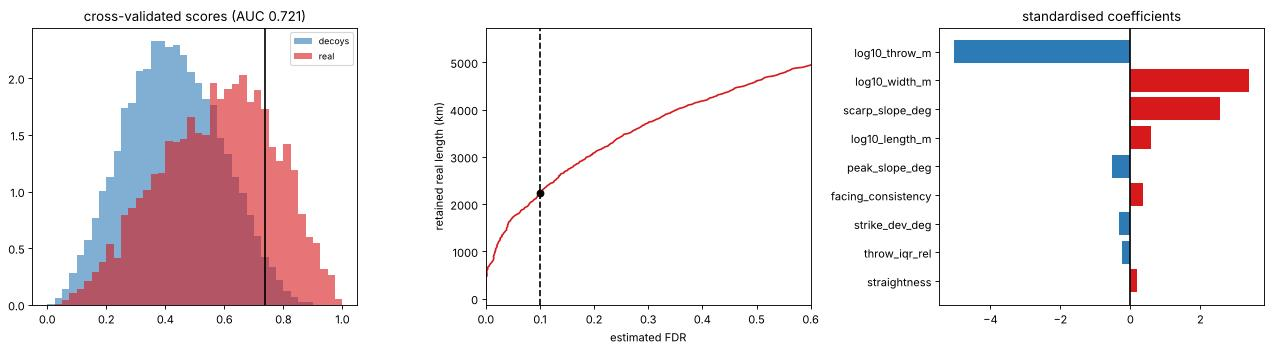

In [17]:
L_r, L_n = L_cand[y == 1], L_cand[y == 0]
ts = np.unique(np.quantile(s_r, np.linspace(0, 0.995, 400)))
real_km_t = np.array([L_r[s_r >= t].sum() for t in ts])
null_km_t = np.array([L_n[s_n >= t].sum() / N_SURROGATES for t in ts])
fdr_t = np.where(real_km_t > 0, null_km_t / np.maximum(real_km_t, 1e-9), np.nan)
ok_t = np.isfinite(fdr_t) & (fdr_t <= FDR_TARGET)
i_t = int(np.argmax(np.where(ok_t, real_km_t, -1))) if ok_t.any() else int(np.nanargmin(fdr_t))
SCORER_THRESHOLD_SEL = float(ts[i_t])
print(f"阈值 p ≥ {SCORER_THRESHOLD_SEL:.4f}：保留 {real_km_t[i_t]:.0f} km，估计 FDR {fdr_t[i_t]:.3f}")

fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
bins_ = np.linspace(0, 1, 41)
axs[0].hist(s_n, bins=bins_, density=True, alpha=0.6, color="#2c7bb6", label="decoys")
axs[0].hist(s_r, bins=bins_, density=True, alpha=0.6, color="#d7191c", label="real")
axs[0].axvline(SCORER_THRESHOLD_SEL, color="k")
axs[0].set_title(f"cross-validated scores (AUC {AUC_CV:.3f})")
axs[0].legend(fontsize=8)
axs[1].plot(fdr_t, real_km_t, "-", color="#d7191c")
axs[1].axvline(FDR_TARGET, color="k", ls="--")
axs[1].plot([fdr_t[i_t]], [real_km_t[i_t]], "ko")
axs[1].set_xlim(0, 0.6)
axs[1].set_xlabel("estimated FDR")
axs[1].set_ylabel("retained real length (km)")
o_ = np.argsort(np.abs(MODEL_COEF))
axs[2].barh(np.array(SCORER_FEATURES)[o_], MODEL_COEF[o_],
            color=["#d7191c" if v > 0 else "#2c7bb6" for v in MODEL_COEF[o_]])
axs[2].axvline(0, color="k")
axs[2].set_title("standardised coefficients")
plt.tight_layout()
plt.show()

---
## 14. 交给实现笔记本的参数

下面打印的内容，由研究员**手动抄写**到实现笔记本的第 5 步。
默认采用机器学习（target-decoy）的接受规则；统计 FDR 的接受阈值作为备选一并列出。

In [18]:
fmt_list = ", ".join
print("# ===== 抄写到实现笔记本「5. 核心参数」=====")
print(f"SIGMA_M = {SIGMA_SEL:.1f}                # 开发笔记本 · 步骤 6")
print(f"ORIENT_TOL_DEG = {ORIENT_TOL:.1f}         # 开发笔记本 · 步骤 5")
print(f"SLOPE_HIGH_DEG = {SLOPE_HIGH_SEL}        # 开发笔记本 · 步骤 7")
print(f"SLOPE_LOW_DEG = {SLOPE_LOW_SEL}")
print(f"STOP_SLOPE_DEG = {STOP_SLOPE_SEL}")
print(f"EDGE_BUFFER_M = {EDGE_BUFFER_SEL:.1f}; SIMPLIFY_TOL_M = {SIMPLIFY_SEL:.1f}; MIN_CANDIDATE_M = {MIN_CANDIDATE_SEL:.1f}")
print("# 机器学习接受规则（开发笔记本 · 步骤 12-13）")
print("MIN_LENGTH_M = 500.0; MIN_THROW_M = 0.0; MAX_STRIKE_DEV_DEG = 90.0; USE_SCORER = True")
print(f"SCORER_FEATURES = {SCORER_FEATURES}")
print("SCORER_MEAN = [" + fmt_list(f"{v:.6g}" for v in MODEL_MEAN) + "]")
print("SCORER_SCALE = [" + fmt_list(f"{v:.6g}" for v in MODEL_SCALE) + "]")
print("SCORER_COEF = [" + fmt_list(f"{v:.6g}" for v in MODEL_COEF) + "]")
print(f"SCORER_INTERCEPT = {MODEL_INTERCEPT:.6g}")
print(f"SCORER_THRESHOLD = {SCORER_THRESHOLD_SEL:.6g}")
print("# 备选：统计 FDR 接受规则（开发笔记本 · 步骤 10）")
print(f"# MIN_LENGTH_M = {STATS_MIN_LENGTH_M:.1f}; MIN_THROW_M = {STATS_MIN_THROW_M:.1f}; "
      f"MAX_STRIKE_DEV_DEG = {STATS_MAX_DEV_DEG:.1f}; USE_SCORER = False")

# ===== 抄写到实现笔记本「5. 核心参数」=====
SIGMA_M = 75.0                # 开发笔记本 · 步骤 6
ORIENT_TOL_DEG = 45.0         # 开发笔记本 · 步骤 5
SLOPE_HIGH_DEG = 12.35        # 开发笔记本 · 步骤 7
SLOPE_LOW_DEG = 8.82
STOP_SLOPE_DEG = 6.82
EDGE_BUFFER_M = 150.0; SIMPLIFY_TOL_M = 30.0; MIN_CANDIDATE_M = 300.0
# 机器学习接受规则（开发笔记本 · 步骤 12-13）
MIN_LENGTH_M = 500.0; MIN_THROW_M = 0.0; MAX_STRIKE_DEV_DEG = 90.0; USE_SCORER = True
SCORER_FEATURES = ['log10_length_m', 'log10_throw_m', 'throw_iqr_rel', 'scarp_slope_deg', 'peak_slope_deg', 'log10_width_m', 'straightness', 'strike_dev_deg', 'facing_consistency']
SCORER_MEAN = [2.97665, 2.14311, 0.409322, 15.6107, 20.5966, 2.70688, 0.939218, 16.3156, 0.962246]
SCORER_SCALE = [0.210443, 0.21825, 0.277425, 3.5875, 5.19331, 0.144503, 0.0490594, 12.1769, 0.0286938]
SCORER_COEF = [0.583723, -5.04096, -0.246409, 2.56599, -0.540208, 3.39513, 0.184188, -0.317642, 0.358989]
SCORER_INTERCEPT = -0.217409
SCORER_THRESHOLD = 0.736845
# 备选：统计 FDR 接受规则（开发笔记本 · 步骤 10）
# MIN_LENGTH_M = 3250.0; MIN

---
## 15. （仅 MAR 29°N）用 CD99 TOBI 侧扫做独立检验

TOBI 是 30 kHz、6 m 分辨率的深拖侧扫声呐，断层的碎屑坡在图像上呈亮色线状条带。它和 GMRT 完全独立，可以用来比较三组参数：
* CD99 手调的参考参数；
* 统计 FDR 接受规则；
* 机器学习接受规则。

对每组参数计算两个指标：
* **精确度代理**：断层迹线（在 TOBI 覆盖范围内）距 TOBI 亮色线状像元 ≤ 400 m 的比例；
* **召回代理**：TOBI 线状像元距断层 ≤ 400 m 的比例。

两者都与"迹线垂直走向随机平移 0.75–2.25 km"得到的随机水平对比。

这里把 TOBI 亮色线状体简化为 **长度 ≥ 1 km 的骨架连通块**，不做矢量化，所以数值和包版本的验证不完全一样，适合用来比较参数组之间的相对好坏。

In [19]:
TOBI_BBOX = (-43.71, -42.65, 28.75, 29.24)
tobi_ok = (RUN_TOBI_CHECK and BBOX[0] < TOBI_BBOX[1] and TOBI_BBOX[0] < BBOX[1]
           and BBOX[2] < TOBI_BBOX[3] and TOBI_BBOX[2] < BBOX[3] and EPSG == 32623)
print("运行 TOBI 检验" if tobi_ok else "跳过 TOBI 检验（区域不重叠或已关闭）")
if tobi_ok:
    # 三组参数下的断层：都来自第 9 步的候选，只是接受规则不同
    fault_sets = {"reference": [], "stats": [], "ml": []}
    for c_ in all_candidates["real_ref"]:
        if c_["length_km"] * 1000 >= 1500.0 and c_["throw_median_m"] >= 40.0:
            fault_sets["reference"].append(c_)
    for c_ in all_candidates["real_auto"]:
        if (c_["length_km"] * 1000 >= STATS_MIN_LENGTH_M and c_["throw_median_m"] >= STATS_MIN_THROW_M
                and c_["features"]["strike_dev_deg"] <= STATS_MAX_DEV_DEG):
            fault_sets["stats"].append(c_)
        if c_["length_km"] * 1000 >= 500.0:
            z_ = (np.array([c_["features"][f] for f in SCORER_FEATURES]) - MODEL_MEAN) / MODEL_SCALE
            if 1 / (1 + np.exp(-(z_ @ MODEL_COEF + MODEL_INTERCEPT))) >= SCORER_THRESHOLD_SEL:
                fault_sets["ml"].append(c_)
    STRIKE = all_strike["real_auto"]
    print({k: len(v) for k, v in fault_sets.items()})

运行 TOBI 检验
{'reference': 579, 'stats': 249, 'ml': 824}


In [20]:
if tobi_ok:
    ax_r, ax_c = np.nonzero(np.isfinite(DEM))
    ax_x, ax_y = X0 + ax_c * PX, Y0 - ax_r * PX
    ax_z = DEM[ax_r, ax_c].astype(float)
    AX_OX, AX_OY = float(np.mean(ax_x)), float(np.mean(ax_y))
    AX_SE, AX_SN = np.sin(np.radians(STRIKE)), np.cos(np.radians(STRIKE))              # 沿走向单位向量
    AX_NE, AX_NN = np.sin(np.radians(STRIKE + 90.0)), np.cos(np.radians(STRIKE + 90.0))  # 垂直走向单位向量
    s_all = (ax_x - AX_OX) * AX_SE + (ax_y - AX_OY) * AX_SN
    n_all = (ax_x - AX_OX) * AX_NE + (ax_y - AX_OY) * AX_NN
    BIN_ALONG, WINDOW_ALONG, BIN_ACROSS, SMOOTH_ACROSS, EDGE_MARGIN, MIN_COUNT = 2000.0, 6000.0, 250.0, 3000.0, 4000.0, 30
    n_edges = np.arange(n_all.min(), n_all.max() + BIN_ACROSS, BIN_ACROSS)
    n_cent = 0.5 * (n_edges[1:] + n_edges[:-1])
    valley_profiles = []
    for s_c in np.arange(s_all.min() + WINDOW_ALONG / 2, s_all.max() - WINDOW_ALONG / 2 + 1, BIN_ALONG):
        sel_ = np.abs(s_all - s_c) <= WINDOW_ALONG / 2
        if sel_.sum() < MIN_COUNT * 10:
            continue
        idx_ = np.digitize(n_all[sel_], n_edges) - 1
        ok_ = (idx_ >= 0) & (idx_ < n_cent.size)
        cnt_ = np.bincount(idx_[ok_], minlength=n_cent.size)
        prof = np.full(n_cent.size, np.nan)
        z_sorted = ax_z[sel_][ok_][np.argsort(idx_[ok_])]
        bounds = np.concatenate([[0], np.cumsum(cnt_)])
        for kb in np.nonzero(cnt_ >= MIN_COUNT)[0]:
            prof[kb] = np.median(z_sorted[bounds[kb]:bounds[kb + 1]])
        good = np.isfinite(prof)
        if good.sum() < 10:
            continue
        sg_ = SMOOTH_ACROSS / BIN_ACROSS
        num_ = ndi.gaussian_filter1d(np.where(good, prof, 0.0), sg_, mode="constant")
        den_ = ndi.gaussian_filter1d(good.astype(float), sg_, mode="constant")
        smp = np.where(den_ > 0.3, num_ / np.maximum(den_, 1e-9), np.nan)
        smp[(n_cent < n_cent[good].min() + EDGE_MARGIN) | (n_cent > n_cent[good].max() - EDGE_MARGIN)] = np.nan
        valley_profiles.append((s_c, smp))
    AXIS_A = AXIS_B = 0.0
    for band in (None, 15000.0, 8000.0, 5000.0):           # 谷底取点 -> Theil-Sen，在收窄的条带内迭代
        picks = []
        for s_c, smp in valley_profiles:
            vals = smp.copy()
            if band is not None:
                vals[np.abs(n_cent - (AXIS_A + AXIS_B * s_c)) > band] = np.nan
            if np.isfinite(vals).any():
                picks.append((s_c, n_cent[np.nanargmin(vals)]))
        picks = np.array(picks)
        AXIS_B, AXIS_A, _, _ = theilslopes(picks[:, 1], picks[:, 0])
    inl = np.abs(picks[:, 1] - (AXIS_A + AXIS_B * picks[:, 0])) <= 4000.0
    if inl.sum() >= 3:
        AXIS_B, AXIS_A, _, _ = theilslopes(picks[inl, 1], picks[inl, 0])
        picks = picks[inl]
    AXIS_S_MIN = float(max(s_all.min(), picks[:, 0].min() - BIN_ALONG))
    AXIS_S_MAX = float(min(s_all.max(), picks[:, 0].max() + BIN_ALONG))
    AXIS_AZIMUTH = float((STRIKE + np.degrees(np.arctan(AXIS_B))) % 180.0)
    FAULT_LIST = [f_ for fs_ in fault_sets.values() for f_ in fs_]
    for f_ in FAULT_LIST:
        mx, my = f_["pix_xy"].mean(axis=0)
        s_f = (mx - AX_OX) * AX_SE + (my - AX_OY) * AX_SN
        n_f = (mx - AX_OX) * AX_NE + (my - AX_OY) * AX_NN
        d_f = (n_f - (AXIS_A + AXIS_B * s_f)) / np.sqrt(1 + AXIS_B ** 2)
        side_f = 1 if f_["facing_side"] == "E" else -1
        f_["dist_axis_km"] = float(d_f / 1000.0)
        f_["flank"] = "E" if d_f > 0 else "W"
        f_["polarity"] = "inward" if side_f * np.sign(d_f) < 0 else "outward"
    print(f"中轴方位 {AXIS_AZIMUTH:.1f}°")

中轴方位 17.4°


In [21]:
if tobi_ok:
    BLOCK = 4
    tobi_num, tobi_cnt = None, None
    for t_name, t_id in (("map_north.tif", "134421.tif"), ("map_south.tif", "134422.tif")):
        t_path = os.path.join(CD99_DIR, t_name)
        if not os.path.exists(t_path):
            os.makedirs(CD99_DIR, exist_ok=True)
            print(f"下载 {t_name}（约 150 MB）")
            for attempt in range(4):
                try:
                    with urllib.request.urlopen(f"https://www.seanoe.org/data/01089/120030/data/{t_id}", timeout=1800) as resp, open(t_path + ".part", "wb") as fh:
                        shutil.copyfileobj(resp, fh, length=1 << 20)
                    os.replace(t_path + ".part", t_path)
                    break
                except Exception as exc:
                    print("下载失败，重试：", exc)
                    time.sleep(2 ** (attempt + 1))
        with tifffile.TiffFile(t_path) as tif:
            pg = tif.pages[0]
            t_scale = pg.tags["ModelPixelScaleTag"].value
            t_tie = pg.tags["ModelTiepointTag"].value
            raw = pg.asarray()
        # 注意：CD99 镶嵌图的 GeoKey 写的是 WGS84，但坐标实际是 UTM 23N 米
        T_DX = float(t_scale[0])
        T_X0 = float(t_tie[3]) + 0.5 * T_DX + (BLOCK - 1) / 2 * T_DX
        T_Y0 = float(t_tie[4]) - 0.5 * T_DX - (BLOCK - 1) / 2 * T_DX
        hh, ww = raw.shape[0] // BLOCK * BLOCK, raw.shape[1] // BLOCK * BLOCK
        vb = raw[:hh, :ww] != 0
        shp = (hh // BLOCK, BLOCK, ww // BLOCK, BLOCK)
        s_b = np.where(vb, raw[:hh, :ww], 0).astype(np.float64).reshape(shp).sum(axis=(1, 3))
        c_b = vb.reshape(shp).sum(axis=(1, 3)).astype(np.float64)
        img_b = np.where(c_b / BLOCK ** 2 >= 0.5, s_b / np.maximum(c_b, 1), np.nan)
        v_b = np.isfinite(img_b)
        sgn = 600.0 / (T_DX * BLOCK)                               # 600 m 局部 z-score 归一化
        a_b = np.where(v_b, img_b, 0.0)
        w_b = ndi.gaussian_filter(v_b.astype(float), sgn)
        m_b = ndi.gaussian_filter(a_b, sgn) / np.maximum(w_b, 1e-6)
        m2_b = ndi.gaussian_filter(a_b * a_b, sgn) / np.maximum(w_b, 1e-6)
        z_b = np.clip((a_b - m_b) / np.sqrt(np.maximum(m2_b - m_b * m_b, 1e-6)), -4, 4)
        z_b[~v_b] = 0.0
        tobi_num = np.where(v_b, z_b, 0) if tobi_num is None else tobi_num + np.where(v_b, z_b, 0)
        tobi_cnt = v_b.astype(float) if tobi_cnt is None else tobi_cnt + v_b
        del raw
    T_PX = T_DX * BLOCK
    tobi_valid = tobi_cnt > 0
    tobi_img = np.where(tobi_valid, tobi_num / np.maximum(tobi_cnt, 1), 0).astype(np.float32)
    # 多尺度、多方向的各向异性脊滤波（沿走向拉长 4 倍的高斯二阶导数）
    best = np.full(tobi_img.shape, -np.inf, np.float32)
    best_ang = np.zeros(tobi_img.shape, np.float32)
    sig_list = [s / T_PX for s in (35.0, 70.0, 140.0)]
    for sg in sig_list:
        for ang in STRIKE + np.arange(-30.0, 30.0 + 1e-6, 5.0):
            sa = 4.0 * sg
            half_k = int(np.ceil(3 * max(sa, sg)))
            kr_, kc_ = np.mgrid[-half_k:half_k + 1, -half_k:half_k + 1].astype(np.float64)
            u_k = kc_ * np.sin(np.radians(ang)) - kr_ * np.cos(np.radians(ang))
            v_k = kc_ * np.cos(np.radians(ang)) + kr_ * np.sin(np.radians(ang))
            g_k = np.exp(-0.5 * (u_k / sa) ** 2 - 0.5 * (v_k / sg) ** 2)
            ker = g_k * (1.0 - (v_k / sg) ** 2)
            ker -= ker.mean() * (g_k / g_k.mean())
            ker /= np.abs(ker).sum()
            resp_k = oaconvolve(tobi_img, ker.astype(np.float32), mode="same").astype(np.float32)
            better = resp_k > best
            best[better] = resp_k[better]
            best_ang[better] = ang % 180.0
    usable = tobi_valid & (ndi.gaussian_filter(tobi_valid.astype(np.float32), max(sig_list) * 2.0) >= 0.6)
    med_r = float(np.median(best[usable]))
    mad_r = float(np.median(np.abs(best[usable] - med_r))) * 1.4826 + 1e-9
    rz = np.where(usable, (best - med_r) / mad_r, 0.0).astype(np.float32)
    ne_t, nn_t = np.sin(np.radians(best_ang + 90.0)), np.cos(np.radians(best_ang + 90.0))
    rr_i, cc_i = np.indices(rz.shape, dtype=np.float64)
    m1 = ndi.map_coordinates(rz, [rr_i - nn_t, cc_i + ne_t], order=1, mode="nearest")
    m2 = ndi.map_coordinates(rz, [rr_i + nn_t, cc_i - ne_t], order=1, mode="nearest")
    edges_t = apply_hysteresis_threshold(np.where((rz >= m1) & (rz >= m2) & usable & (rz >= 2.5), rz, 0.0), 2.5, 4.0)
    skel_t = skeletonize(edges_t)
    lab_t, n_lab_t = ndi.label(skel_t, structure=np.ones((3, 3)))
    sz_t = ndi.sum(skel_t, lab_t, np.arange(1, n_lab_t + 1))
    keep_t = np.zeros(n_lab_t + 1, bool)
    keep_t[1:] = sz_t * T_PX >= 1000.0
    tobi_lin = keep_t[lab_t]
    dist_tobi = ndi.distance_transform_edt(~tobi_lin) * T_PX
    covered_t = ndi.binary_dilation(tobi_valid, iterations=2)
    del rr_i, cc_i, m1, m2, best, best_ang
    print(f"TOBI 网格 {tobi_img.shape[1]} x {tobi_img.shape[0]} @ {T_PX:.0f} m；线状像元 {int(tobi_lin.sum())} 个（{int(keep_t.sum())} 段）")

TOBI 网格 4228 x 2220 @ 24 m；线状像元 17327 个（262 段）


参数组           条数     km |    精确度     随机 |     召回     随机 |     内倾     随机 |     外倾     随机
reference    579   1626 |  0.212  0.122 |  0.333  0.195 |  0.231  0.113 |  0.173  0.141
stats        249   1266 |  0.228  0.118 |  0.245  0.140 |  0.252  0.111 |  0.174  0.133
ml           824   2236 |  0.202  0.131 |  0.390  0.266 |  0.262  0.122 |  0.096  0.147


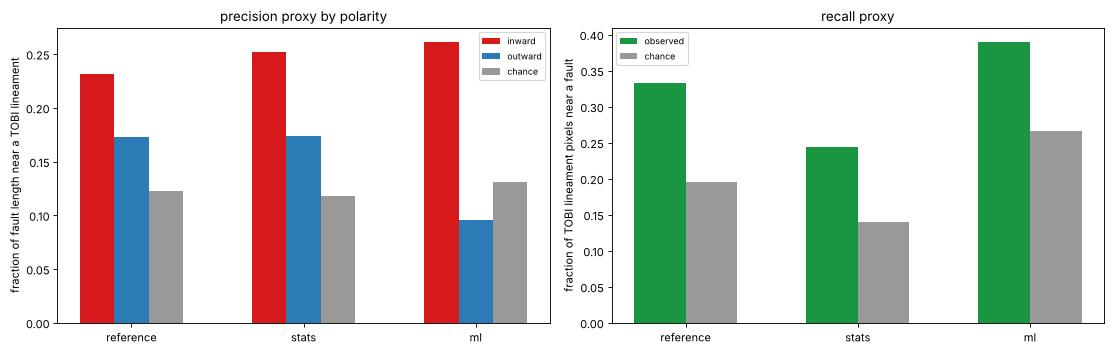

In [22]:
if tobi_ok:
    rng_t = np.random.default_rng(SEED)
    shifts = [float(rng_t.choice([-1, 1]) * 1500.0 * rng_t.uniform(0.5, 1.5)) for _ in range(6)]
    tobi_r, tobi_c = np.nonzero(tobi_lin)
    rows_out = {}
    for set_name, fs_ in fault_sets.items():
        res_row = {"n": len(fs_), "km": sum(f_["length_km"] for f_ in fs_)}
        for subset, members in (("all", fs_), ("inward", [f_ for f_ in fs_ if f_["polarity"] == "inward"]),
                                ("outward", [f_ for f_ in fs_ if f_["polarity"] == "outward"])):
            pts = []
            for f_ in members:                                   # 每 50 m 取一个点
                seg_l = np.hypot(*np.diff(f_["xy"], axis=0).T)
                cum_l = np.concatenate([[0], np.cumsum(seg_l)])
                t_l = np.linspace(0, cum_l[-1], max(int(np.ceil(cum_l[-1] / 50.0)), 1) + 1)
                pts.append(np.column_stack([np.interp(t_l, cum_l, f_["xy"][:, 0]), np.interp(t_l, cum_l, f_["xy"][:, 1])]))
            pts = np.vstack(pts) if pts else np.zeros((0, 2))
            prec_vals = []
            for off in [0.0] + shifts:
                px_ = pts[:, 0] + off * AX_NE
                py_ = pts[:, 1] + off * AX_NN
                tr_ = np.round((T_Y0 - py_) / T_PX).astype(int)
                tc_ = np.round((px_ - T_X0) / T_PX).astype(int)
                in_ = (tr_ >= 0) & (tr_ < tobi_lin.shape[0]) & (tc_ >= 0) & (tc_ < tobi_lin.shape[1])
                cov_ = np.zeros(len(pts), bool)
                cov_[in_] = covered_t[tr_[in_], tc_[in_]]
                dd_ = np.full(len(pts), np.inf)
                dd_[in_] = dist_tobi[tr_[in_], tc_[in_]]
                prec_vals.append(float(np.mean(dd_[cov_] <= 400.0)) if cov_.any() else np.nan)
            res_row[f"prec_{subset}"] = prec_vals[0]
            res_row[f"prec_{subset}_chance"] = float(np.nanmean(prec_vals[1:]))
            if subset == "all":
                rec_vals = []
                for off in [0.0] + shifts[:3]:
                    burn = np.zeros(tobi_lin.shape, bool)
                    tr_ = np.round((T_Y0 - (pts[:, 1] + off * AX_NN)) / T_PX).astype(int)
                    tc_ = np.round(((pts[:, 0] + off * AX_NE) - T_X0) / T_PX).astype(int)
                    in_ = (tr_ >= 0) & (tr_ < burn.shape[0]) & (tc_ >= 0) & (tc_ < burn.shape[1])
                    burn[tr_[in_], tc_[in_]] = True
                    dist_f = ndi.distance_transform_edt(~burn) * T_PX
                    rec_vals.append(float(np.mean(dist_f[tobi_r, tobi_c] <= 400.0)))
                res_row["recall"], res_row["recall_chance"] = rec_vals[0], float(np.mean(rec_vals[1:]))
        rows_out[set_name] = res_row
    print(f"{'参数组':10s} {'条数':>5s} {'km':>6s} | {'精确度':>6s} {'随机':>6s} | {'召回':>6s} {'随机':>6s} | "
          f"{'内倾':>6s} {'随机':>6s} | {'外倾':>6s} {'随机':>6s}")
    for set_name, r_ in rows_out.items():
        print(f"{set_name:10s} {r_['n']:5d} {r_['km']:6.0f} | {r_['prec_all']:6.3f} {r_['prec_all_chance']:6.3f} | "
              f"{r_['recall']:6.3f} {r_['recall_chance']:6.3f} | {r_['prec_inward']:6.3f} {r_['prec_inward_chance']:6.3f} | "
              f"{r_['prec_outward']:6.3f} {r_['prec_outward_chance']:6.3f}")
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
    names_ = list(rows_out)
    xpos = np.arange(len(names_))
    axs[0].bar(xpos - 0.2, [rows_out[n]["prec_inward"] for n in names_], 0.2, color="#d7191c", label="inward")
    axs[0].bar(xpos, [rows_out[n]["prec_outward"] for n in names_], 0.2, color="#2c7bb6", label="outward")
    axs[0].bar(xpos + 0.2, [rows_out[n]["prec_all_chance"] for n in names_], 0.2, color="0.6", label="chance")
    axs[0].set_xticks(xpos)
    axs[0].set_xticklabels(names_)
    axs[0].set_ylabel("fraction of fault length near a TOBI lineament")
    axs[0].legend(fontsize=8)
    axs[0].set_title("precision proxy by polarity")
    axs[1].bar(xpos - 0.15, [rows_out[n]["recall"] for n in names_], 0.3, color="#1a9641", label="observed")
    axs[1].bar(xpos + 0.15, [rows_out[n]["recall_chance"] for n in names_], 0.3, color="0.6", label="chance")
    axs[1].set_xticks(xpos)
    axs[1].set_xticklabels(names_)
    axs[1].set_ylabel("fraction of TOBI lineament pixels near a fault")
    axs[1].legend(fontsize=8)
    axs[1].set_title("recall proxy")
    plt.tight_layout()
    plt.show()

---
## 16. 数据导出：每个参数的数值与数据传递文件

把本笔记本得出的全部核心参数逐项输出：数值、单位、来自哪一步。
`EXPORT_TRANSFER_FILE = True` 时，再把同样的数值写成一份**数据传递文件**（JSON）。在网页版（PWA）「识别参数 → 上传文件」里上传它，
就相当于把这些数值逐项填进网页，不必手动抄写。实现笔记本仍按第 14 步手动抄写，不读取这个文件。

* 文件里的数值与第 14 步打印的数值**逐位相同**（同样的格式和有效数字），所以网页导入后的结果与实现笔记本一致。
* `KEEP_OUTWARD` 由第 15 步决定：只有当外倾陡坎的精确度代理高出随机水平的部分，至少达到内倾陡坎的一半时，才保留外倾陡坎；没有做第 15 步时不做外倾筛选。
* 文件还记录了数据集（区域、分辨率、投影、网格）、统计 FDR 备选方案，以及研究诊断（有效分辨率、Ashman D、交叉验证 AUC、估计 FDR、TOBI 检验），方便核对。

In [23]:
EXPORT_TRANSFER_FILE = True                                   # 是否导出数据传递文件（给网页版导入）
TRANSFER_FILE = f"gmrt_fault_params_{AOI_NAME}.json"          # 数据传递文件的路径

# 1) KEEP_OUTWARD：第 15 步的结论（用机器学习接受规则那一组断层）
if tobi_ok:
    r_ml = rows_out["ml"]
    excess_in = r_ml["prec_inward"] - r_ml["prec_inward_chance"]
    excess_out = r_ml["prec_outward"] - r_ml["prec_outward_chance"]
    KEEP_OUTWARD_SEL = bool(excess_out >= 0.5 * excess_in)
    keep_note = (f"步骤 15：外倾陡坎精确度 {r_ml['prec_outward']:.3f}（随机 {r_ml['prec_outward_chance']:.3f}），"
                 f"内倾 {r_ml['prec_inward']:.3f}（随机 {r_ml['prec_inward_chance']:.3f}）")
else:
    KEEP_OUTWARD_SEL = True
    keep_note = "没有做步骤 15 的独立检验：不做外倾筛选"

# 2) 每个参数的数值：与第 14 步打印的数值逐位相同
EXPORT = {
    "SIGMA_M": float(f"{SIGMA_SEL:.1f}"),
    "ORIENT_TOL_DEG": float(f"{ORIENT_TOL:.1f}"),
    "SLOPE_HIGH_DEG": float(SLOPE_HIGH_SEL),
    "SLOPE_LOW_DEG": float(SLOPE_LOW_SEL),
    "STOP_SLOPE_DEG": float(STOP_SLOPE_SEL),
    "EDGE_BUFFER_M": float(f"{EDGE_BUFFER_SEL:.1f}"),
    "SIMPLIFY_TOL_M": float(f"{SIMPLIFY_SEL:.1f}"),
    "MIN_CANDIDATE_M": float(f"{MIN_CANDIDATE_SEL:.1f}"),
    "MIN_LENGTH_M": 500.0,
    "MIN_THROW_M": 0.0,
    "MAX_STRIKE_DEV_DEG": 90.0,
    "USE_SCORER": True,
    "SCORER_FEATURES": list(SCORER_FEATURES),
    "SCORER_MEAN": [float(f"{v:.6g}") for v in MODEL_MEAN],
    "SCORER_SCALE": [float(f"{v:.6g}") for v in MODEL_SCALE],
    "SCORER_COEF": [float(f"{v:.6g}") for v in MODEL_COEF],
    "SCORER_INTERCEPT": float(f"{MODEL_INTERCEPT:.6g}"),
    "SCORER_THRESHOLD": float(f"{SCORER_THRESHOLD_SEL:.6g}"),
    "KEEP_OUTWARD": KEEP_OUTWARD_SEL,
    "STRIKE_FIXED": None,
    "REL_STOP": REL_STOP,
    "RISE_TOL_DEG": RISE_TOL_DEG,
    "MAX_WALK_M": MAX_WALK_M,
    "MIN_PIXEL_THROW_M": MIN_PIXEL_THROW_M,
    "LINK_GAP_M": LINK_GAP_M,
    "LINK_ANGLE_DEG": LINK_ANGLE_DEG,
}
ALT_STATS = {"MIN_LENGTH_M": float(f"{STATS_MIN_LENGTH_M:.1f}"), "MIN_THROW_M": float(f"{STATS_MIN_THROW_M:.1f}"),
             "MAX_STRIKE_DEV_DEG": float(f"{STATS_MAX_DEV_DEG:.1f}"), "USE_SCORER": False}
PARAM_INFO = {                                                # 参数名: (单位, 来源与说明)
    "SIGMA_M": ("m", "步骤 6：尺度选择（脊线坡度双峰程度 Ashman D 最大）"),
    "ORIENT_TOL_DEG": ("°", "步骤 5：纹理方向统计（80% 权重半宽，限制在 20–45°）"),
    "SLOPE_HIGH_DEG": ("°", "步骤 7：坡度混合模型后验 P(陡坎) = 0.9"),
    "SLOPE_LOW_DEG": ("°", "步骤 7：后验 P(陡坎) = 0.5"),
    "STOP_SLOPE_DEG": ("°", "步骤 7：坡度第 30 百分位（坡折）"),
    "EDGE_BUFFER_M": ("m", "步骤 7：max(2 像元, 2σ)"),
    "SIMPLIFY_TOL_M": ("m", "步骤 7：max(0.6 像元, 30 m)"),
    "MIN_CANDIDATE_M": ("m", "步骤 7：max(300 m, 6 像元)"),
    "MIN_LENGTH_M": ("m", "步骤 12–13：机器学习接受规则"),
    "MIN_THROW_M": ("m", "步骤 12–13：机器学习接受规则"),
    "MAX_STRIKE_DEV_DEG": ("°", "步骤 12–13：机器学习接受规则"),
    "USE_SCORER": ("", "步骤 12–13：使用 target-decoy 逻辑回归评分器"),
    "SCORER_FEATURES": ("", "步骤 12：评分器使用的形态特征"),
    "SCORER_MEAN": ("", "步骤 12：特征标准化的均值"),
    "SCORER_SCALE": ("", "步骤 12：特征标准化的尺度"),
    "SCORER_COEF": ("", "步骤 12：标准化后的逻辑回归系数"),
    "SCORER_INTERCEPT": ("", "步骤 12：逻辑回归截距"),
    "SCORER_THRESHOLD": ("", f"步骤 13：估计 FDR {fdr_t[i_t]:.3f}（目标 {FDR_TARGET}）时的 P(断层) 阈值"),
    "KEEP_OUTWARD": ("", keep_note),
    "STRIKE_FIXED": ("°", "固定常数：None = 用结构张量自动估计区域走向"),
    "REL_STOP": ("", "固定常数：坡度 < REL_STOP × 峰值坡度时视为到达坡折"),
    "RISE_TOL_DEG": ("°", "固定常数：坡度回升超过它视为进入下一条陡坎"),
    "MAX_WALK_M": ("m", "固定常数：沿倾向最远走的距离"),
    "MIN_PIXEL_THROW_M": ("m", "固定常数：单个中心线像元的最小断距"),
    "LINK_GAP_M": ("m", "固定常数：连接共线线段的最大间隙"),
    "LINK_ANGLE_DEG": ("°", "固定常数：连接时允许的最大方向变化"),
}

# 3) 逐项输出每个数据
print(f"数据集 {AOI_NAME}：区域 {BBOX}，GMRT {GMRT_RES}，EPSG:{EPSG}，{PX:.0f} m 网格 {NX} x {NY}")
print(f"{'参数':18s}{'数值':>14s}  单位  来源与说明")
for k_, v_ in EXPORT.items():
    if isinstance(v_, list):
        continue
    u_, note_ = PARAM_INFO[k_]
    print(f"{k_:20s}{repr(v_):>14s}  {u_:4s}{note_}")
print(f"评分器（步骤 12–13）：{len(EXPORT['SCORER_FEATURES'])} 个特征")
print(f"  {'特征':18s}{'均值':>10s}{'尺度':>12s}{'系数':>12s}")
for f_, m_, s_, c_ in zip(EXPORT["SCORER_FEATURES"], EXPORT["SCORER_MEAN"], EXPORT["SCORER_SCALE"], EXPORT["SCORER_COEF"]):
    print(f"  {f_:20s}{m_:>12g}{s_:>14g}{c_:>+14g}")
print("备选方案（步骤 10，统计 FDR，更保守）：" + "；".join(f"{k_} = {v_}" for k_, v_ in ALT_STATS.items()))

# 4) 可选：数据传递文件（JSON）
TRANSFER = {
    "format": "gmrt-fault-params",
    "format_version": 1,
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "producer": "GMRT_fault_development.ipynb",
    "dataset": {"aoi_name": AOI_NAME, "bbox": [float(v) for v in BBOX], "gmrt_res": GMRT_RES, "epsg": int(EPSG),
                "pixel_m": float(PX), "grid": [int(NX), int(NY)], "valid_frac": round(float(np.isfinite(DEM).mean()), 4)},
    "params": EXPORT,
    "alternatives": {"stats_fdr": ALT_STATS},
    "units": {k_: u_ for k_, (u_, _) in PARAM_INFO.items()},
    "notes": {k_: note_ for k_, (_, note_) in PARAM_INFO.items()},
    "diagnostics": {
        "effective_resolution_m": float(LAMBDA_EFF), "spectral_beta": float(BETA), "noise_m": float(NOISE_M),
        "fabric_strike_deg": float(FABRIC_STRIKE), "orient_tol80_deg": float(TOL80),
        "ashman_d": {f"{r_['sigma_m']:.0f}": float(r_["ashman_d"]) for r_ in scale_table},
        "fdr_target": float(FDR_TARGET), "n_surrogates": int(N_SURROGATES), "seed": int(SEED),
        "stats_fdr": {"estimated_fdr": float(FDR[best_idx]), "retained_km": float(REAL_KM[best_idx])},
        "ml": {"cv_auc": float(AUC_CV), "estimated_fdr": float(fdr_t[i_t]), "retained_km": float(real_km_t[i_t]),
               "n_target": len(tgt), "n_decoy": len(dec)},
        "feature_auc": {k_: float(v_) for k_, v_ in auc_table.items()},
        "tobi_check": ({k_: {kk_: (None if isinstance(vv_, float) and not np.isfinite(vv_) else vv_) for kk_, vv_ in r_.items()}
                        for k_, r_ in rows_out.items()} if tobi_ok else None),
    },
}
if EXPORT_TRANSFER_FILE:
    with open(TRANSFER_FILE, "w", encoding="utf-8") as fh:
        json.dump(TRANSFER, fh, ensure_ascii=False, indent=1, allow_nan=False)
    print(f"已导出数据传递文件 {os.path.abspath(TRANSFER_FILE)}（{os.path.getsize(TRANSFER_FILE) / 1024:.1f} KB）")
    print("在网页版「识别参数 → 上传文件」里上传它即可；实现笔记本仍按第 14 步手动抄写。")
else:
    print("EXPORT_TRANSFER_FILE = False：只输出数值，不导出文件")

数据集 mar29n：区域 (-43.75, -42.55, 28.74, 29.36)，GMRT max，EPSG:32623，50 m 网格 2360 x 1414
参数                            数值  单位  来源与说明
SIGMA_M                       75.0  m   步骤 6：尺度选择（脊线坡度双峰程度 Ashman D 最大）
ORIENT_TOL_DEG                45.0  °   步骤 5：纹理方向统计（80% 权重半宽，限制在 20–45°）
SLOPE_HIGH_DEG               12.35  °   步骤 7：坡度混合模型后验 P(陡坎) = 0.9
SLOPE_LOW_DEG                 8.82  °   步骤 7：后验 P(陡坎) = 0.5
STOP_SLOPE_DEG                6.82  °   步骤 7：坡度第 30 百分位（坡折）
EDGE_BUFFER_M                150.0  m   步骤 7：max(2 像元, 2σ)
SIMPLIFY_TOL_M                30.0  m   步骤 7：max(0.6 像元, 30 m)
MIN_CANDIDATE_M              300.0  m   步骤 7：max(300 m, 6 像元)
MIN_LENGTH_M                 500.0  m   步骤 12–13：机器学习接受规则
MIN_THROW_M                    0.0  m   步骤 12–13：机器学习接受规则
MAX_STRIKE_DEV_DEG            90.0  °   步骤 12–13：机器学习接受规则
USE_SCORER                    True      步骤 12–13：使用 target-decoy 逻辑回归评分器
SCORER_INTERCEPT         -0.217409      步骤 12：逻辑回归截距
SCORER_THRESHOLD          0.736845      步骤 13：估计 FDR 0.1

### 研究结论

* 第 14 步打印的参数，已经手动抄写到实现笔记本的第 5 步（实现笔记本不读取本笔记本的任何文件）。
* 第 15 步的独立检验决定 `KEEP_OUTWARD`：如果外倾陡坎与 TOBI 的一致度和随机水平差不多，说明它们大多不是断层，实现笔记本就设 `KEEP_OUTWARD = False`。
* 第 16 步逐项输出全部参数，并可选导出数据传递文件 `gmrt_fault_params_<区域名>.json`。网页版上传这个文件，等于把这些数值逐项填进网页。